# Caso de Estudio de Machine Learning clásico — Ames Housing
## Estimación del precio de venta de viviendas: preparación de datos, modelado y evaluación

### ¿Qué es este notebook?

Este notebook construye, evalúa y deja listo para usar un modelo que estima el **precio de venta de una vivienda** de Ames (Iowa, EE. UU.) a partir de sus características observables: tamaño, ubicación, calidad de construcción, estado de conservación y condiciones de la operación. Es la solución ejecutable del caso de estudio: contiene todo el recorrido, desde la carga de los datos hasta el archivo de predicciones para el test que evaluará el equipo docente.

El modelo produce una **estimación inicial y reproducible**. No reemplaza una tasación profesional ni debe usarse para decidir créditos; sirve para tener un primer valor y para señalar qué viviendas necesitan revisión humana.

### Pregunta que ordena el trabajo

> ¿Qué decisiones de preparación de datos y de modelado explican el mejor desempeño alcanzado, y con qué evidencia las sostenemos?

Cada decisión del notebook está respaldada por un experimento medido con el mismo esquema de evaluación, y la sección 15 responde la pregunta con esos resultados.

### Datos

- `train.csv`: 1.022 viviendas vendidas entre 2006 y 2010, con 79 variables explicativas, un identificador (`Id`) y el precio (`SalePrice`).
- `validation.csv`: 219 viviendas con las mismas columnas, que reservamos como partición de validación y que no interviene en ninguna decisión.
- `test.csv`: el archivo que entregará la cátedra, con las mismas columnas y sin `SalePrice`.

El significado de cada variable está en `data_description.txt`. El análisis exploratorio completo está en el notebook `EDA_Ames_Housing.ipynb`; acá retomamos sus conclusiones y las convertimos en decisiones de preparación.

### Cómo ejecutarlo

1. Tener Python 3.10 o superior con `scikit-learn` (≥ 1.2), `pandas`, `numpy`, `scipy` y `matplotlib`. No se instala nada desde el notebook. Esta versión del notebook se ejecutó con scikit-learn 1.9.1 y pandas 3.0.5; también se verificó con scikit-learn 1.6.1 y pandas 2.2.3, donde el modelo elegido y sus métricas son idénticos y solo cambian en decenas de dólares los modelos de árboles de las secciones 5 y 7.
2. Dejar los CSV en alguna de estas carpetas, relativas al notebook: `data/`, la misma carpeta del notebook o `../ames-housing-desarrollo-estudiantes/`.
3. Copiar el archivo de test en esa misma carpeta con el nombre `test.csv`. La ruta está definida una sola vez, en `TEST_PATH`, en la primera celda de código.
4. Ejecutar todas las celdas en orden (*Run all*). Tarda unos 6 minutos en una máquina de 2 núcleos.

Las predicciones quedan en `predicciones_test.csv` (columnas `Id` y `SalePrice`). No hay que editar ninguna línea: si `test.csv` todavía no está, el notebook corre igual y avisa en la sección 13.

### Estructura

| Sección | Contenido |
|---|---|
| 1 | Configuración: rutas, semillas y parámetros de evaluación |
| 2 | Carga y auditoría de los datos |
| 3 | Esquema de evaluación y métricas |
| 4 | Preparación de los datos: valores atípicos, target, faltantes, codificación y variables nuevas |
| 5 | Experimentos de preparación |
| 6 – 8 | Modelos candidatos, ajuste de hiperparámetros, ensambles y elección del modelo |
| 9 | Tabla de experimentos y decisiones |
| 10 – 11 | Evaluación en validación y análisis de errores |
| 12 | Verificaciones de fuga de datos y reproducibilidad |
| 13 | Modelo final y predicciones para el archivo de test |
| 14 – 16 | Límites de la solución, conclusiones y fuentes |

### Convenciones

- El código está en inglés; la documentación, los títulos de los gráficos y los mensajes están en español.
- Todas las métricas se informan **en dólares**, sobre precios ya convertidos desde la escala logarítmica.
- Las tablas que genera el código usan coma como separador de miles (`$20,167`); en el texto usamos punto (USD 20.167).

## 1. Configuración

### 1.1 Rutas de los datos

Esta es la única celda donde se definen rutas. El notebook busca `train.csv` en las carpetas candidatas y toma el archivo de test de **`TEST_PATH`**: ese es el único lugar que determina qué archivo se predice en la sección 13.

In [1]:
from pathlib import Path

# Folders where the data may live, relative to this notebook. The first one containing train.csv is used.
DATA_DIR_CANDIDATES = [
    Path("data"),
    Path("."),
    Path("../ames-housing-desarrollo-estudiantes"),
    Path("ames-housing-desarrollo-estudiantes"),
]
DATA_DIR = next((folder for folder in DATA_DIR_CANDIDATES if (folder / "train.csv").is_file()), None)
if DATA_DIR is None:
    raise FileNotFoundError(
        "No se encontró train.csv. Copiá los CSV en una de estas carpetas: "
        + ", ".join(str(folder) for folder in DATA_DIR_CANDIDATES)
    )

TRAIN_PATH = DATA_DIR / "train.csv"            # development data (with SalePrice)
VALIDATION_PATH = DATA_DIR / "validation.csv"  # hold-out partition (with SalePrice)
TEST_PATH = DATA_DIR / "test.csv"              # <<< TEST FILE: same columns, without SalePrice
PREDICTIONS_PATH = Path("predicciones_test.csv")  # output written by section 13

print(f"Carpeta de datos : {DATA_DIR}")
print(f"Archivo de test  : {TEST_PATH}  ({'encontrado' if TEST_PATH.is_file() else 'todavía no está'})")

Carpeta de datos : ../ames-housing-desarrollo-estudiantes
Archivo de test  : ../ames-housing-desarrollo-estudiantes/test.csv  (todavía no está)


### 1.2 Librerías, semillas y parámetros de evaluación

Para que cada ejecución dé exactamente los mismos resultados fijamos una semilla (`RANDOM_STATE = 42`) en todos los lugares donde interviene el azar:

| Paso con aleatoriedad | Cómo se fija |
|---|---|
| Armado de los folds de validación cruzada (y de la partición de validación, si hubiera que crearla) | `random_state` en `RepeatedKFold`, `KFold` y `train_test_split` |
| Combinaciones de hiperparámetros que prueba la búsqueda aleatoria | `random_state` en `RandomizedSearchCV` |
| Muestreo de filas y columnas en Random Forest y Gradient Boosting | `random_state` en cada modelo |
| Folds internos del Stacking | `random_state` en su `KFold` |
| Importancia por permutación y prueba del target mezclado | `random_state` explícito |

ElasticNet (descenso por coordenadas cíclico) y SVR son deterministas. El paralelismo (`n_jobs=-1`) no altera los resultados: cada tarea recibe su semilla y el orden de ejecución no influye.

In [2]:
import platform
import random
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
from IPython.display import display
from joblib import Parallel, delayed
from scipy import special, stats
from scipy.stats import loguniform, randint, uniform

from sklearn.base import BaseEstimator, OneToOneFeatureMixin, TransformerMixin, clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import (
    GradientBoostingRegressor,
    RandomForestRegressor,
    StackingRegressor,
    VotingRegressor,
)
from sklearn.exceptions import ConvergenceWarning
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import ElasticNet, LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, RandomizedSearchCV, RepeatedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.svm import SVR

# ---------------------------------------------------------------- reproducibility
RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

# ---------------------------------------------------------------- evaluation design
N_SPLITS = 5              # folds per cross-validation round
N_REPEATS = 3             # rounds of the repeated cross-validation used to compare configurations
HOLDOUT_FRACTION = 0.18   # only used if validation.csv is not delivered with the data
SEARCH_ITERATIONS = {"ElasticNet": 40, "SVR": 30, "RandomForest": 8, "GradientBoosting": 20}
N_JOBS = -1

# ---------------------------------------------------------------- schema
TARGET = "SalePrice"
ID_COLUMN = "Id"

warnings.filterwarnings("ignore", category=ConvergenceWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False,
                     "axes.spines.right": False})

print(f"Python {platform.python_version()} | scikit-learn {sklearn.__version__} | pandas {pd.__version__} "
      f"| numpy {np.__version__} | scipy {scipy.__version__}")

Python 3.13.18 | scikit-learn 1.9.1 | pandas 3.0.5 | numpy 2.5.3 | scipy 1.18.1


## 2. Datos de desarrollo y auditoría

Los datos de desarrollo con los que trabajamos están separados en dos archivos: `train.csv` (entrenamiento) y `validation.csv` (validación). Usamos esa separación fija como partición de validación. Si `validation.csv` no estuviera en la carpeta, la función de carga arma la partición a partir de `train.csv` con una semilla fija y estratificando por quintil de precio, de modo que el notebook corre en los dos casos.

Antes de modelar verificamos tres condiciones que, de fallar, invalidarían cualquier resultado: que el precio sea siempre positivo (necesario para el logaritmo), que ningún `Id` se repita y que ninguna vivienda aparezca en las dos particiones, porque una vivienda repetida sería una fuga de información: el modelo ya habría visto su precio.

In [3]:
def load_development_data():
    """Return the (train, validation) partitions and a description of how the hold-out was obtained."""
    train = pd.read_csv(TRAIN_PATH)
    if VALIDATION_PATH.is_file():
        return train, pd.read_csv(VALIDATION_PATH), "archivo validation.csv entregado junto a train.csv"
    # Fallback: build the hold-out from train.csv, stratified by price quintile so both parts are comparable.
    price_bins = pd.qcut(train[TARGET], q=5, labels=False)
    train, validation = train_test_split(train, test_size=HOLDOUT_FRACTION, stratify=price_bins,
                                         random_state=RANDOM_STATE)
    return (train.reset_index(drop=True), validation.reset_index(drop=True),
            f"partición estratificada propia ({HOLDOUT_FRACTION:.0%} de train.csv, semilla {RANDOM_STATE})")


train_df, validation_df, holdout_origin = load_development_data()
FEATURE_COLUMNS = [column for column in train_df.columns if column not in (ID_COLUMN, TARGET)]

print(f"Entrenamiento : {train_df.shape[0]} viviendas x {train_df.shape[1]} columnas")
print(f"Validación    : {validation_df.shape[0]} viviendas ({holdout_origin})")
print(f"Variables explicativas: {len(FEATURE_COLUMNS)}")

Entrenamiento : 1022 viviendas x 81 columnas
Validación    : 219 viviendas (archivo validation.csv entregado junto a train.csv)
Variables explicativas: 79


In [4]:
def feature_fingerprints(frame):
    """One hashable key per house, built from every explanatory column (used to detect duplicates)."""
    as_text = frame[FEATURE_COLUMNS].apply(
        lambda column: column.astype(float).astype(str) if pd.api.types.is_numeric_dtype(column)
        else column.astype(str))
    return set(map(tuple, as_text.to_numpy()))


assert list(validation_df.columns) == list(train_df.columns), "Las particiones no tienen las mismas columnas."
assert (train_df[TARGET] > 0).all() and (validation_df[TARGET] > 0).all(), "SalePrice debe ser positivo."
assert train_df[ID_COLUMN].is_unique and validation_df[ID_COLUMN].is_unique, "Hay Id repetidos."
shared_ids = set(train_df[ID_COLUMN]) & set(validation_df[ID_COLUMN])
shared_houses = feature_fingerprints(train_df) & feature_fingerprints(validation_df)
assert not shared_ids and not shared_houses, "Hay viviendas presentes en ambas particiones."

missing_share = train_df[FEATURE_COLUMNS].isna().mean().sort_values(ascending=False)
audit = pd.DataFrame({
    "Entrenamiento": [len(train_df), train_df[TARGET].median(), train_df[TARGET].mean(),
                      train_df[TARGET].min(), train_df[TARGET].max()],
    "Validación": [len(validation_df), validation_df[TARGET].median(), validation_df[TARGET].mean(),
                   validation_df[TARGET].min(), validation_df[TARGET].max()],
}, index=["Viviendas", "Precio mediano (USD)", "Precio medio (USD)", "Precio mínimo (USD)", "Precio máximo (USD)"])
display(audit.style.format("{:,.0f}"))
print(f"Id compartidos: {len(shared_ids)} | viviendas idénticas entre particiones: {len(shared_houses)}")
print(f"Columnas con faltantes en entrenamiento: {(missing_share > 0).sum()} de {len(FEATURE_COLUMNS)}")
print("Mayor proporción de faltantes:",
      ", ".join(f"{column} {share:.0%}" for column, share in missing_share.head(6).items()))

,Entrenamiento,Validación
Viviendas,"1,022",219
Precio mediano (USD),"163,000","164,900"
Precio medio (USD),"180,928","183,337"
Precio mínimo (USD),"35,311","39,300"
Precio máximo (USD),"755,000","611,657"


Id compartidos: 0 | viviendas idénticas entre particiones: 0
Columnas con faltantes en entrenamiento: 19 de 79
Mayor proporción de faltantes: PoolQC 99%, MiscFeature 96%, Alley 93%, Fence 80%, MasVnrType 60%, FireplaceQu 48%


**Lectura.** Las dos particiones son independientes (ningún `Id` ni vivienda en común) y comparables: el precio mediano es de USD 163.000 en entrenamiento y USD 164.900 en validación. La vivienda más cara de validación (USD 611.657) está por debajo de las más caras de entrenamiento (USD 755.000), así que validación no exige extrapolar precios. De las 79 variables, 19 tienen faltantes, pero en las que más faltan (`PoolQC` 99 %, `MiscFeature` 96 %, `Alley` 93 %, `Fence` 80 %) el vacío no es un dato perdido sino la ausencia de la característica; lo tratamos en la sección 4.3.

## 3. Esquema de evaluación y métricas

**Métricas.** La métrica oficial es el **RMSE en dólares**, que penaliza con fuerza los errores grandes. La acompañamos con el **MAE en dólares**, que mide el error típico sin exagerar los casos extremos; la distancia entre ambas indica cuánto pesan unas pocas viviendas muy mal estimadas. Como apoyo calculamos el RMSLE (RMSE entre logaritmos de los precios, cercano al error relativo típico), el MAPE y el R².

**Tres niveles de datos, cada uno con un único uso:**

| Datos | Para qué se usan | Para qué no |
|---|---|---|
| Entrenamiento (`train.csv`) con validación cruzada | Comparar preparaciones, ajustar hiperparámetros y elegir el modelo | — |
| Validación (`validation.csv`) | Informar el desempeño del modelo ya elegido y analizar sus errores | No interviene en ninguna decisión |
| Test (`test.csv`, sin precio) | Generar las predicciones que evalúa la cátedra | No se puede medir nada sobre él |

**Un solo esquema para comparar.** Todas las configuraciones se miden con la misma función, `evaluate_cv`: validación cruzada de 5 folds repetida 3 veces (15 evaluaciones) sobre las mismas particiones. En cada fold el flujo completo (imputaciones, codificaciones, escalado y modelo) se ajusta desde cero con las cuatro quintas partes de entrenamiento y se mide sobre la quinta restante, en dólares. Repetimos la validación cruzada porque con unas 200 viviendas por fold el RMSE depende mucho de qué viviendas caras caen en cada uno: una sola repetición puede ordenar mal dos modelos parecidos.

Como todos los modelos se evalúan sobre los mismos 15 folds, las comparaciones son **pareadas**: informamos la diferencia media de RMSE entre dos configuraciones y su error estándar. Una diferencia menor que dos errores estándar no se distingue del ruido.

Las búsquedas de hiperparámetros usan una sola ronda de 5 folds (la primera del mismo esquema) para mantener el tiempo de ejecución en pocos minutos; los modelos ya ajustados se comparan después con el esquema completo.

In [5]:
def rmse(y_true, y_pred):
    """Root mean squared error, the official metric (USD)."""
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))


def rmsle(y_true, y_pred):
    """RMSE between log prices: close to the typical relative error."""
    return rmse(np.log1p(y_true), np.log1p(np.clip(y_pred, 1.0, None)))


def score_predictions(y_true, y_pred):
    """All metrics are computed on prices in dollars."""
    y_true, y_pred = np.asarray(y_true, dtype=float), np.asarray(y_pred, dtype=float)
    return {
        "RMSE": rmse(y_true, y_pred),
        "MAE": float(mean_absolute_error(y_true, y_pred)),
        "RMSLE": rmsle(y_true, y_pred),
        "MAPE_%": float(100 * np.mean(np.abs(y_true - y_pred) / y_true)),
        "R2": float(r2_score(y_true, y_pred)),
    }


# Same folds for every configuration compared in this notebook.
CV = RepeatedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=RANDOM_STATE)
# Hyperparameter searches use one round of the same design to keep the run time reasonable.
SEARCH_CV = KFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)


def _fit_and_score_fold(estimator, X, y, train_index, test_index, extra_train):
    X_fit, y_fit = X.iloc[train_index], y.iloc[train_index]
    if extra_train is not None:  # rows that may be learned from but are never used to score
        X_fit = pd.concat([X_fit, extra_train.drop(columns=[TARGET])], ignore_index=True)
        y_fit = pd.concat([y_fit, extra_train[TARGET]], ignore_index=True)
    model = clone(estimator).fit(X_fit, y_fit)
    return score_predictions(y.iloc[test_index], model.predict(X.iloc[test_index]))


def evaluate_cv(estimator, X, y, extra_train=None):
    """Repeated K-fold evaluation in dollars. Each fold refits the whole flow from scratch."""
    fold_scores = Parallel(n_jobs=N_JOBS)(
        delayed(_fit_and_score_fold)(estimator, X, y, train_index, test_index, extra_train)
        for train_index, test_index in CV.split(X))
    fold_scores = pd.DataFrame(fold_scores)
    return {
        "RMSE_CV": fold_scores["RMSE"].mean(),
        "RMSE_CV_std": fold_scores["RMSE"].std(ddof=1),
        "MAE_CV": fold_scores["MAE"].mean(),
        "RMSLE_CV": fold_scores["RMSLE"].mean(),
        "fold_rmse": fold_scores["RMSE"].to_numpy(),
    }


experiment_log = []


def run_experiment(experiment_id, preparation, model_description, estimator, X, y, extra_train=None):
    """Evaluate one configuration with the shared scheme and append it to the experiment log."""
    scores = evaluate_cv(estimator, X, y, extra_train=extra_train)
    experiment_log.append({"ID": experiment_id, "Preparación": preparation, "Modelo": model_description,
                           **scores})
    return scores


USD_FORMAT = {"RMSE_CV": "${:,.0f}", "RMSE_CV_std": "${:,.0f}", "MAE_CV": "${:,.0f}", "RMSLE_CV": "{:.4f}",
              "RMSE": "${:,.0f}", "MAE": "${:,.0f}", "RMSLE": "{:.4f}", "MAPE_%": "{:.1f}%", "R2": "{:.3f}"}


def show(table, extra_format=None):
    """Display a table with money columns formatted as dollars."""
    formats = {**USD_FORMAT, **(extra_format or {})}
    display(table.style.format({column: fmt for column, fmt in formats.items() if column in table.columns}))

## 4. Preparación de los datos

El EDA dejó una lista de hallazgos. Esta tabla muestra en qué decisión se convirtió cada uno y dónde se pone a prueba:

| Hallazgo del EDA | Decisión | Sección | Experimento |
|---|---|---|---|
| Dos viviendas de más de 4.000 pies² vendidas muy por debajo del resto | Excluirlas del entrenamiento con una regla fija | 4.1 | P3 |
| `SalePrice` asimétrico (asimetría 1,95) | Modelar `log1p(SalePrice)` y devolver dólares | 4.2 | P2 |
| La mayoría de los faltantes significan "no tiene" | Categoría `"None"` o cero según la variable; imputación solo para los faltantes reales | 4.3 | P4 |
| Variables de calidad con orden natural; `MSSubClass` es un código | Codificación ordinal; `MSSubClass` como categoría | 4.4 | P5 |
| `Neighborhood` (25 niveles) y otras categóricas con muchos niveles | One-hot agrupando los niveles con menos de 10 viviendas | 4.5 | P6 |
| Superficies muy asimétricas y variables "casi siempre en cero" | `log1p` en las superficies continuas; indicadores de presencia | 4.4 – 4.5 | P7, P8 |
| Escalas muy distintas entre variables | Estandarizar para los modelos lineales y de kernel | 4.5 | — |
| Pares de variables muy correlacionadas | Probar quitar una de cada par | 4.5 | P9 |
| Niveles que aparecen solo en validación (`Exterior1st = Stone`, `GarageQual = Ex`) | Codificadores que aceptan niveles no vistos | 4.5 | Verificación 5 |

Todo lo que se aprende de los datos vive dentro del flujo y se ajusta solo con los datos de entrenamiento de cada fold.

### 4.1 Valores extremos: dos ventas atípicas

El EDA encontró dos viviendas con más de 4.000 pies² de superficie habitable y un precio menor a USD 300.000. La documentación del dataset (De Cock, 2011) las señala como ventas que no representan valores de mercado y recomienda quitar del dataset las viviendas de más de 4.000 pies². Nosotros adaptamos esa recomendación: excluimos solo las dos mal valuadas y conservamos las otras dos viviendas de ese tamaño, que se vendieron a USD 745.000 y USD 755.000, un precio coherente con su superficie.

La regla se define con umbrales fijos, tomados del EDA antes de modelar, y se aplica **únicamente a los datos de entrenamiento**. En validación y en test no se elimina nada: la regla necesita el precio, que en test no existe, y sacar casos difíciles de validación haría que el error informado fuera mejor que el real.

Id,GrLivArea,OverallQual,SaleCondition,SalePrice,USD_por_pie2
100365,5642,10,Partial,"$160,000",$28
100219,4676,10,Partial,"$184,750",$40


Precio mediano por pie² en entrenamiento: USD 120
Viviendas que cumplen la regla -> entrenamiento: 2 (se excluyen del ajuste) | validación: 0 (nunca se eliminan)


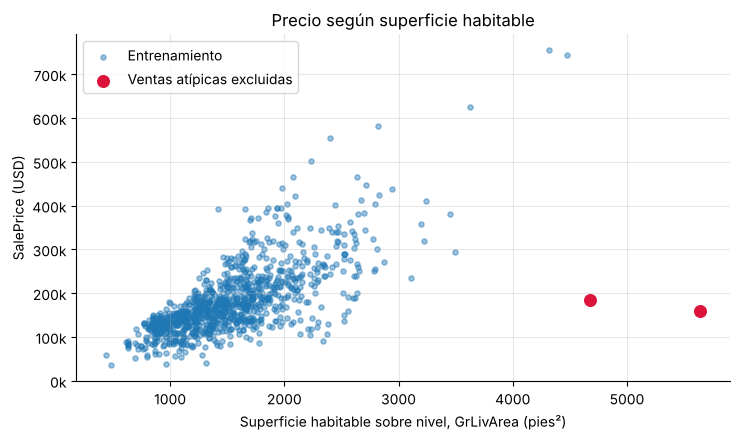

In [6]:
OUTLIER_MIN_LIVING_AREA = 4000   # square feet (GrLivArea)
OUTLIER_MAX_PRICE = 300_000      # USD


def atypical_sale_mask(frame):
    """Very large houses sold far below what their size implies (rule fixed beforehand, from the EDA)."""
    return (frame["GrLivArea"] > OUTLIER_MIN_LIVING_AREA) & (frame[TARGET] < OUTLIER_MAX_PRICE)


outlier_rows = train_df[atypical_sale_mask(train_df)]
train_clean = train_df[~atypical_sale_mask(train_df)].reset_index(drop=True)

X_train, y_train = train_clean.drop(columns=[TARGET]), train_clean[TARGET]
X_validation, y_validation = validation_df.drop(columns=[TARGET]), validation_df[TARGET]

median_price_per_sqft = (train_df[TARGET] / train_df["GrLivArea"]).median()
display(outlier_rows[[ID_COLUMN, "GrLivArea", "OverallQual", "SaleCondition", TARGET]]
        .assign(USD_por_pie2=lambda rows: rows[TARGET] / rows["GrLivArea"])
        .style.format({TARGET: "${:,.0f}", "USD_por_pie2": "${:,.0f}"}).hide(axis="index"))
print(f"Precio mediano por pie² en entrenamiento: USD {median_price_per_sqft:,.0f}")
print(f"Viviendas que cumplen la regla -> entrenamiento: {len(outlier_rows)} (se excluyen del ajuste) | "
      f"validación: {int(atypical_sale_mask(validation_df).sum())} (nunca se eliminan)")

fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.scatter(train_clean["GrLivArea"], train_clean[TARGET], s=14, alpha=0.45, label="Entrenamiento")
ax.scatter(outlier_rows["GrLivArea"], outlier_rows[TARGET], s=70, color="crimson", label="Ventas atípicas excluidas")
ax.set(xlabel="Superficie habitable sobre nivel, GrLivArea (pies²)", ylabel="SalePrice (USD)",
       title="Precio según superficie habitable")
ax.yaxis.set_major_formatter(lambda value, _: f"{value / 1000:,.0f}k")
ax.legend()
plt.tight_layout()
plt.show()

**Lectura.** Las dos viviendas se vendieron a USD 28 y USD 40 por pie², contra una mediana de USD 120. Ambas tienen calidad general 10 y condición de venta `Partial`, que en el diccionario de datos corresponde a viviendas sin terminar al momento de tasarlas: el precio registrado no refleja la casa terminada. En el gráfico son los dos puntos rojos, muy por debajo de la tendencia. Para un modelo son dos ejemplos que dicen "más superficie y más calidad, menos precio", lo contrario de lo que muestran las otras 1.020 viviendas. El experimento P3 mide cuánto cuesta dejarlas.

En validación ninguna vivienda cumple la regla. Si en el test hubiera alguna, el modelo la sobrestimaría por mucho: es una limitación que retomamos en la sección 14.

### 4.2 Variable objetivo: logaritmo del precio

`SalePrice` tiene una cola larga hacia los precios altos. Entrenamos sobre `log1p(SalePrice)` por dos motivos: en esa escala los errores son relativos (equivocarse un 10 % pesa lo mismo en una casa de USD 100.000 que en una de USD 400.000) y la relación con las variables principales se vuelve aproximadamente lineal, que es lo que suponen los modelos lineales.

La transformación está dentro del flujo (`TransformedTargetRegressor`): al ajustar aplica `log1p` al precio y al predecir aplica `expm1`, de modo que el modelo siempre recibe y devuelve dólares. Es una función fija, sin parámetros que aprender, por lo que no puede filtrar información.

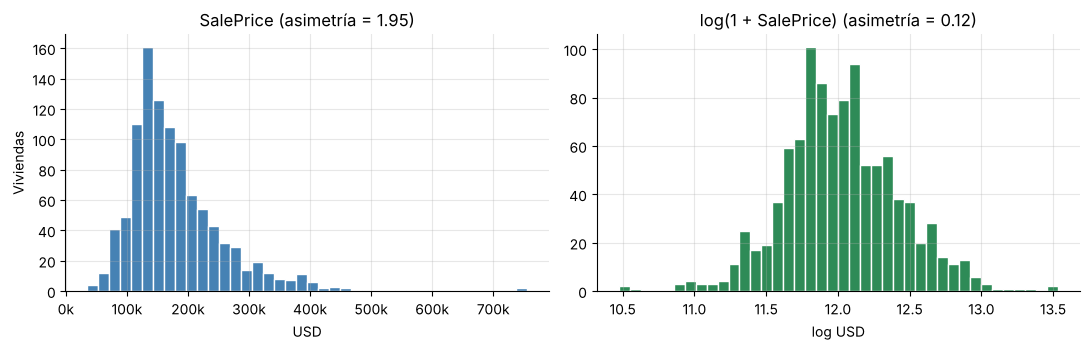

Asimetría de SalePrice: 1.95 -> de log1p(SalePrice): 0.12


In [7]:
log_price = np.log1p(y_train)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].hist(y_train, bins=40, color="steelblue", edgecolor="white")
axes[0].set(title=f"SalePrice (asimetría = {stats.skew(y_train):.2f})", xlabel="USD", ylabel="Viviendas")
axes[0].xaxis.set_major_formatter(lambda value, _: f"{value / 1000:,.0f}k")
axes[1].hist(log_price, bins=40, color="seagreen", edgecolor="white")
axes[1].set(title=f"log(1 + SalePrice) (asimetría = {stats.skew(log_price):.2f})", xlabel="log USD")
plt.tight_layout()
plt.show()
print(f"Asimetría de SalePrice: {stats.skew(y_train):.2f} -> de log1p(SalePrice): {stats.skew(log_price):.2f}")

**Lectura.** La asimetría baja de 1,95 a 0,12: en escala logarítmica la distribución es casi simétrica. Un costo a tener presente es que un modelo que minimiza el error en logaritmos apunta a acertar en términos relativos, mientras que la métrica oficial se mide en dólares y la dominan las viviendas caras. Por eso todas las comparaciones del notebook se hacen en dólares, y el experimento P2 mide si el logaritmo realmente conviene con esa métrica.

### 4.3 Faltantes: distinguir "no tiene" de "no se sabe"

`data_description.txt` define `NA` como una categoría válida en varias variables: sin pileta, sin garage, sin sótano, sin cerco. Tratamos cada caso según su significado:

| Situación | Variables | Tratamiento | Dónde se aprende |
|---|---|---|---|
| La característica no existe (categórica) | `PoolQC`, `MiscFeature`, `Alley`, `Fence`, `FireplaceQu`, `MasVnrType`, las cuatro de garage y las cinco de sótano | Categoría explícita `"None"` | Regla fija |
| La característica no existe (numérica) | `MasVnrArea`, superficies y baños de sótano, `GarageCars`, `GarageArea` | Cero | Regla fija |
| Año del garage en una casa sin garage | `GarageYrBlt` | Se reemplaza por la antigüedad del garage (igual a la de la casa si no tiene) más el indicador `HasGarage` | Regla fija |
| Dato realmente desconocido | `LotFrontage` | Mediana del barrio; si el barrio es nuevo, mediana global | Entrenamiento |
| Dato realmente desconocido | `Electrical` y cualquier otra categórica | Nivel más frecuente | Entrenamiento |
| Dato realmente desconocido | Cualquier otra numérica | Mediana | Entrenamiento |

Imputar la moda o la mediana en las primeras tres filas sería un error conceptual: a una casa sin garage se le asignaría un garage "típico". Las dos últimas filas no hacen falta con los datos actuales, pero dejan el flujo preparado para un archivo de test que traiga faltantes en columnas donde entrenamiento no los tiene.

In [8]:
NO_FEATURE = "None"

# Categorical columns where NA means "the house does not have this feature" (data_description.txt).
ABSENCE_CATEGORICAL = [
    "Alley", "MasVnrType", "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2",
    "FireplaceQu", "GarageType", "GarageFinish", "GarageQual", "GarageCond", "PoolQC", "Fence",
    "MiscFeature",
]
# Numeric columns where NA can only mean "no such feature", i.e. a quantity of zero.
ABSENCE_NUMERIC = [
    "MasVnrArea", "BsmtFinSF1", "BsmtFinSF2", "BsmtUnfSF", "TotalBsmtSF", "BsmtFullBath",
    "BsmtHalfBath", "GarageCars", "GarageArea",
]
# Numeric dtype but nominal meaning (dwelling type code).
NUMERIC_CODED_NOMINAL = ["MSSubClass"]

# Ordered levels, from worst to best. "None" (feature absent) is the lowest level where it applies.
QUALITY_LEVELS = [NO_FEATURE, "Po", "Fa", "TA", "Gd", "Ex"]
BASEMENT_FINISH_LEVELS = [NO_FEATURE, "Unf", "LwQ", "Rec", "BLQ", "ALQ", "GLQ"]
ORDINAL_LEVELS = {
    "LotShape": ["IR3", "IR2", "IR1", "Reg"],
    "LandSlope": ["Sev", "Mod", "Gtl"],
    "ExterQual": QUALITY_LEVELS,
    "ExterCond": QUALITY_LEVELS,
    "BsmtQual": QUALITY_LEVELS,
    "BsmtCond": QUALITY_LEVELS,
    "BsmtExposure": [NO_FEATURE, "No", "Mn", "Av", "Gd"],
    "BsmtFinType1": BASEMENT_FINISH_LEVELS,
    "BsmtFinType2": BASEMENT_FINISH_LEVELS,
    "HeatingQC": QUALITY_LEVELS,
    "KitchenQual": QUALITY_LEVELS,
    "FireplaceQu": QUALITY_LEVELS,
    "GarageFinish": [NO_FEATURE, "Unf", "RFn", "Fin"],
    "GarageQual": QUALITY_LEVELS,
    "GarageCond": QUALITY_LEVELS,
    "PoolQC": QUALITY_LEVELS,
    "Functional": ["Sal", "Sev", "Maj2", "Maj1", "Mod", "Min2", "Min1", "Typ"],
    "CentralAir": ["N", "Y"],
    "PavedDrive": ["N", "P", "Y"],
}
QUALITY_SCORE_COLUMNS = ["ExterQual", "KitchenQual", "BsmtQual", "HeatingQC", "GarageQual", "FireplaceQu"]
PORCH_COLUMNS = ["OpenPorchSF", "EnclosedPorch", "3SsnPorch", "ScreenPorch", "WoodDeckSF"]
PRESENCE_FLAGS = {"HasGarage": "GarageArea", "HasBasement": "TotalBsmtSF", "HasFireplace": "Fireplaces",
                  "HasPool": "PoolArea", "HasSecondFloor": "2ndFlrSF", "HasMasonryVeneer": "MasVnrArea"}
# Continuous, non-negative size variables that are candidates for skew correction.
SKEW_CANDIDATES = [
    "LotArea", "LotFrontage", "MasVnrArea", "BsmtFinSF1", "BsmtUnfSF", "TotalBsmtSF", "1stFlrSF",
    "2ndFlrSF", "GrLivArea", "GarageArea", "WoodDeckSF", "OpenPorchSF", "TotalSF", "TotalPorchSF",
    "LivLotRatio", "AvgRoomSize", "QualTimesLivArea", "QualTimesTotalSF",
]
# One variable of each highly correlated pair found in the EDA (only used by experiment P9).
REDUNDANT_COLUMNS = ["GarageArea", "TotRmsAbvGrd", "1stFlrSF"]

unknown_columns = [column for column in (ABSENCE_CATEGORICAL + ABSENCE_NUMERIC + NUMERIC_CODED_NOMINAL
                                         + list(ORDINAL_LEVELS) + PORCH_COLUMNS + REDUNDANT_COLUMNS)
                   if column not in FEATURE_COLUMNS]
assert not unknown_columns, f"Columnas del diccionario de datos ausentes en train.csv: {unknown_columns}"

absence_summary = pd.DataFrame({
    "Faltantes en entrenamiento": train_df[ABSENCE_CATEGORICAL + ABSENCE_NUMERIC].isna().sum(),
    "Tratamiento": ["categoría 'None'"] * len(ABSENCE_CATEGORICAL) + ["cero"] * len(ABSENCE_NUMERIC),
})
absence_summary.loc["GarageYrBlt"] = [train_df["GarageYrBlt"].isna().sum(), "se reemplaza por GarageAge + HasGarage"]
real_missing = [column for column in FEATURE_COLUMNS
                if train_df[column].isna().any() and column not in absence_summary.index]
display(absence_summary[absence_summary["Faltantes en entrenamiento"] > 0])
print("Faltantes reales (dato desconocido) en entrenamiento:",
      {column: int(train_df[column].isna().sum()) for column in real_missing})

,Faltantes en entrenamiento,Tratamiento
Alley,950,categoría 'None'
MasVnrType,612,categoría 'None'
BsmtQual,23,categoría 'None'
BsmtCond,23,categoría 'None'
BsmtExposure,23,categoría 'None'
BsmtFinType1,23,categoría 'None'
BsmtFinType2,24,categoría 'None'
FireplaceQu,486,categoría 'None'
GarageType,50,categoría 'None'
GarageFinish,50,categoría 'None'


Faltantes reales (dato desconocido) en entrenamiento: {'LotFrontage': 186, 'Electrical': 1}


**Lectura.** De los faltantes de entrenamiento, casi todos son ausencias con significado: van desde 1.015 viviendas sin pileta hasta 23 sin sótano. Los 6 faltantes de `MasVnrArea` corresponden a viviendas que tampoco informan tipo de revestimiento, y los tomamos como superficie cero. Los únicos datos realmente desconocidos son `LotFrontage` (186 viviendas, 18 %) y `Electrical` (1 vivienda). Usamos la mediana por barrio para `LotFrontage` porque el frente del lote depende del trazado de cada zona.

### 4.4 Limpieza, codificación ordinal y variables nuevas

`AmesFeatureEngineer` es el primer paso del flujo. Recibe el DataFrame tal como sale del CSV y hace tres cosas:

1. **Limpieza con significado:** aplica las reglas de la sección 4.3, descarta `Id` y convierte `MSSubClass` (un código de tipo de vivienda) en categoría. También fija el esquema: recuerda qué columnas eran numéricas y cuáles categóricas en entrenamiento y fuerza ese tipo en los datos nuevos, de modo que una columna que llegue vacía en el test no cambie de tipo.
2. **Estadísticos aprendidos en `fit`:** las medianas de `LotFrontage` por barrio y las columnas nominales casi constantes (un mismo nivel en el 99 % o más de las viviendas), que se descartan porque no aportan variación.
3. **Variables nuevas**, calculadas fila por fila:

| Variable | Idea |
|---|---|
| `TotalSF`, `TotalBathrooms`, `TotalPorchSF` | Superficie y baños totales: quien compra piensa en el total, no en cada planta |
| `HouseAge`, `RemodelAge`, `GarageAge`, `IsRemodeled`, `IsNew` | Antigüedad y renovación al momento de la venta |
| `HasGarage`, `HasBasement`, `HasFireplace`, `HasPool`, `HasSecondFloor`, `HasMasonryVeneer` | Indicadores de presencia para las variables "casi siempre en cero" |
| `QualityScore` | Suma de seis calidades parciales (exterior, cocina, sótano, calefacción, garage, chimenea) |
| `OverallQualSquared`, `QualTimesLivArea`, `QualTimesTotalSF` | Un pie² de una casa de calidad 9 vale más que uno de calidad 4 |
| `LivLotRatio`, `AvgRoomSize` | Ocupación del terreno y tamaño medio de los ambientes |

**Variables ordinales.** Las calidades y condiciones (`ExterQual`, `KitchenQual`, `BsmtQual`, …) tienen un orden natural: `Po < Fa < TA < Gd < Ex`. Las codificamos como enteros respetando ese orden, con `"None"` (no tiene) como nivel más bajo. La lista de niveles sale del diccionario de datos, no de los datos, así que un nivel válido que no aparezca en entrenamiento (como `GarageQual = Ex`, que solo está en validación) queda bien ubicado.

`SkewCorrector` es el transformador que corrige la asimetría de las superficies. En `fit` decide qué columnas transformar (asimetría mayor a 0,75 en valor absoluto y menos de la mitad de los valores en cero) y, si se usa Box-Cox, estima el exponente de cada una; en `transform` solo aplica lo aprendido.

In [9]:
def is_numeric(series):
    return pd.api.types.is_numeric_dtype(series)


class AmesFeatureEngineer(BaseEstimator, TransformerMixin):
    """Semantic cleaning and feature construction for the Ames Housing schema.

    Row-wise rules (absence -> "None"/0, engineered features) need no fitting. Everything that is
    estimated from data (LotFrontage medians, near-constant columns, column types) is learned in
    fit() and only re-applied in transform().
    """

    def __init__(self, semantic_missing=True, add_features=True, drop_columns=(),
                 quasi_constant_threshold=0.99):
        self.semantic_missing = semantic_missing
        self.add_features = add_features
        self.drop_columns = drop_columns
        self.quasi_constant_threshold = quasi_constant_threshold

    def _clean(self, X):
        """Stateless cleaning: drop identifiers, normalise dtypes and encode 'feature absent'."""
        X = pd.DataFrame(X).drop(columns=[ID_COLUMN, TARGET], errors="ignore").copy()
        for column in X.columns:
            if is_numeric(X[column]):
                X[column] = X[column].astype(float).replace([np.inf, -np.inf], np.nan)
            else:
                X[column] = X[column].astype(object).where(X[column].notna(), np.nan)
        for column in NUMERIC_CODED_NOMINAL:
            codes = pd.to_numeric(X[column], errors="coerce")
            X[column] = codes.map(lambda code: str(int(code)) if pd.notna(code) else np.nan).astype(object)
        if self.semantic_missing:
            for column in ABSENCE_CATEGORICAL:
                X[column] = X[column].astype(object).fillna(NO_FEATURE)
            for column in ABSENCE_NUMERIC:
                X[column] = pd.to_numeric(X[column], errors="coerce").fillna(0.0)
        return X

    def fit(self, X, y=None):
        cleaned = self._clean(X)
        self.feature_names_in_ = np.asarray(cleaned.columns, dtype=object)
        self.numeric_columns_ = [column for column in cleaned.columns if is_numeric(cleaned[column])]
        self.categorical_columns_ = [column for column in cleaned.columns if column not in self.numeric_columns_]
        if self.semantic_missing:
            self.lot_frontage_by_neighborhood_ = cleaned.groupby("Neighborhood")["LotFrontage"].median()
            self.lot_frontage_median_ = float(cleaned["LotFrontage"].median())
        # Nominal columns where a single level covers (almost) every house carry no usable signal.
        self.quasi_constant_columns_ = [
            column for column in self.categorical_columns_
            if column not in ORDINAL_LEVELS
            and cleaned[column].fillna("NA").value_counts(normalize=True).iloc[0] >= self.quasi_constant_threshold
        ]
        self.feature_names_out_ = np.asarray(self._build(cleaned).columns, dtype=object)
        return self

    def _build(self, X):
        """Apply the learned schema and imputations, then add the engineered features."""
        for column in self.numeric_columns_:
            X[column] = pd.to_numeric(X[column], errors="coerce")
        for column in self.categorical_columns_:
            X[column] = X[column].astype(object)
        if self.semantic_missing:
            by_neighborhood = X["Neighborhood"].map(self.lot_frontage_by_neighborhood_)
            X["LotFrontage"] = X["LotFrontage"].fillna(by_neighborhood).fillna(self.lot_frontage_median_)
        if self.add_features:
            X = self._add_features(X)
        return X.drop(columns=self.quasi_constant_columns_ + list(self.drop_columns), errors="ignore")

    @staticmethod
    def _add_features(X):
        def zero_filled(column):
            return X[column].fillna(0.0)

        new = {}
        # Size: buyers reason about the total area, not about each floor separately.
        # (TotalSF and the skew correction are adapted from Serigne, "Stacked Regressions", Kaggle.)
        new["TotalSF"] = zero_filled("TotalBsmtSF") + zero_filled("1stFlrSF") + zero_filled("2ndFlrSF")
        new["TotalBathrooms"] = (zero_filled("FullBath") + 0.5 * zero_filled("HalfBath")
                                 + zero_filled("BsmtFullBath") + 0.5 * zero_filled("BsmtHalfBath"))
        new["TotalPorchSF"] = sum(zero_filled(column) for column in PORCH_COLUMNS)
        # Age at sale, clipped at zero because a few houses are sold before being finished.
        new["HouseAge"] = (X["YrSold"] - X["YearBuilt"]).clip(lower=0)
        new["RemodelAge"] = (X["YrSold"] - X["YearRemodAdd"]).clip(lower=0)
        new["IsRemodeled"] = (X["YearRemodAdd"] != X["YearBuilt"]).astype(float)
        new["IsNew"] = (X["YrSold"] <= X["YearBuilt"]).astype(float)
        garage_year = np.minimum(X["GarageYrBlt"].fillna(X["YearBuilt"]), X["YrSold"])
        new["GarageAge"] = (X["YrSold"] - garage_year).clip(lower=0)
        # Presence flags for "mostly zero" variables.
        for flag, source in PRESENCE_FLAGS.items():
            new[flag] = (zero_filled(source) > 0).astype(float)
        # Composite quality and quality x size interactions.
        quality_points = {level: points for points, level in enumerate(QUALITY_LEVELS)}
        new["QualityScore"] = sum(X[column].map(quality_points).fillna(0.0).astype(float)
                                  for column in QUALITY_SCORE_COLUMNS)
        new["OverallQualSquared"] = X["OverallQual"] ** 2
        new["QualTimesLivArea"] = X["OverallQual"] * X["GrLivArea"]
        new["QualTimesTotalSF"] = X["OverallQual"] * new["TotalSF"]
        # Ratios (a zero denominator becomes NaN and is imputed downstream).
        new["LivLotRatio"] = X["GrLivArea"] / X["LotArea"].replace(0, np.nan)
        new["AvgRoomSize"] = X["GrLivArea"] / X["TotRmsAbvGrd"].replace(0, np.nan)
        # GarageYrBlt is replaced by GarageAge: a year has no meaning for a house without garage.
        return pd.concat([X.drop(columns=["GarageYrBlt"]), pd.DataFrame(new, index=X.index)], axis=1)

    def transform(self, X):
        cleaned = self._clean(X)
        missing = [column for column in self.feature_names_in_ if column not in cleaned.columns]
        if missing:
            raise ValueError(f"Faltan columnas requeridas en los datos de entrada: {missing}")
        return self._build(cleaned[list(self.feature_names_in_)])

    def get_feature_names_out(self, input_features=None):
        return self.feature_names_out_


class SkewCorrector(OneToOneFeatureMixin, TransformerMixin, BaseEstimator):
    """Power-transform skewed non-negative columns.

    Which columns are transformed (|skewness| above the threshold, not dominated by zeros) and, for
    Box-Cox, which lambda each one gets are learned in fit(). method="log" uses lambda = 0 (log1p).
    """

    def __init__(self, method="log", skew_threshold=0.75, max_zero_share=0.5, lambda_bounds=(-2.0, 2.0)):
        self.method = method
        self.skew_threshold = skew_threshold
        self.max_zero_share = max_zero_share
        self.lambda_bounds = lambda_bounds

    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        self.n_features_in_ = X.shape[1]
        self.skewness_ = stats.skew(X, axis=0)
        self.lambdas_ = np.zeros(X.shape[1])
        if self.method == "none":
            self.selected_ = np.zeros(X.shape[1], dtype=bool)
            return self
        self.selected_ = ((np.abs(self.skewness_) > self.skew_threshold) & (X.min(axis=0) >= 0)
                          & ((X == 0).mean(axis=0) <= self.max_zero_share))
        if self.method == "boxcox":
            for index in np.flatnonzero(self.selected_):
                best_lambda = stats.boxcox_normmax(X[:, index] + 1.0, method="mle")
                self.lambdas_[index] = float(np.clip(best_lambda, *self.lambda_bounds))
        return self

    def transform(self, X):
        X = np.asarray(X, dtype=float).copy()
        for index in np.flatnonzero(self.selected_):
            # Box-Cox on 1 + x; lambda = 0 is exactly log1p.
            X[:, index] = special.boxcox1p(np.clip(X[:, index], 0, None), self.lambdas_[index])
        return X


engineer_preview = AmesFeatureEngineer().fit(X_train)
engineered_preview = engineer_preview.transform(X_train)
print(f"Columnas de entrada: {X_train.shape[1]} -> columnas tras la limpieza y la ingeniería: {engineered_preview.shape[1]}")
print("Columnas casi constantes descartadas:", engineer_preview.quasi_constant_columns_)
print("Faltantes que quedan para los imputadores del pipeline:",
      {column: int(count) for column, count in engineered_preview.isna().sum().items() if count > 0})

Columnas de entrada: 80 -> columnas tras la limpieza y la ingeniería: 95
Columnas casi constantes descartadas: ['Street', 'Utilities', 'Condition2']
Faltantes que quedan para los imputadores del pipeline: {'Electrical': 1}


**Lectura.** Las 80 columnas del archivo pasan a ser 95 después de la limpieza y las variables nuevas. Se descartan tres columnas casi constantes (`Street`, `Utilities`, `Condition2`). El único faltante que llega a los imputadores del pipeline es el de `Electrical`; el resto ya quedó resuelto por las reglas de ausencia y por la mediana de `LotFrontage`.

### 4.5 Flujo completo: del DataFrame crudo al precio en dólares

El flujo tiene tres etapas encadenadas en un `Pipeline`, envuelto en la transformación del target:

`AmesFeatureEngineer` → `ColumnTransformer` (imputar, codificar, escalar por tipo de columna) → modelo

| Tipo de columna | Tratamiento |
|---|---|
| Superficies continuas asimétricas | Mediana → `log1p` si la asimetría supera 0,75 → estandarización |
| Resto de las numéricas | Mediana → estandarización |
| Ordinales | Moda → enteros ordenados → estandarización |
| Nominales | Moda → one-hot agrupando en una sola columna los niveles con menos de 10 viviendas |

**Variables categóricas con muchos niveles.** `Neighborhood` tiene 25 niveles, `MSSubClass` 15 y `Exterior1st`/`Exterior2nd` 13 y 14, varios con muy pocas viviendas. Un one-hot directo crea columnas que se estiman con dos o tres ejemplos. Con `min_frequency=10` los niveles con menos de 10 viviendas comparten una única columna "poco frecuente", y los niveles que nunca se vieron en entrenamiento caen en esa misma columna en lugar de producir un error.

**Escalado.** ElasticNet penaliza el tamaño de los coeficientes y SVR mide distancias entre viviendas: en los dos casos una variable en miles de pies² dominaría a una calidad de 1 a 10 si no se estandarizan. Los modelos de árboles dividen por umbrales, que no cambian con la escala ni con transformaciones monótonas, así que para ellos se omiten el escalado y la corrección de asimetría.

`build_pipeline` arma el flujo y acepta opciones que permiten apagar cada decisión por separado; así se construyen los experimentos de la sección 5.

In [10]:
def skewed_columns(X):
    return [column for column in SKEW_CANDIDATES if column in X.columns]


def other_numeric_columns(X):
    return [column for column in X.columns if is_numeric(X[column]) and column not in SKEW_CANDIDATES]


def nominal_columns(X):
    return [column for column in X.columns if not is_numeric(X[column]) and column not in ORDINAL_LEVELS]


def categorical_columns(X):
    return [column for column in X.columns if not is_numeric(X[column])]


def build_preprocessor(scale=True, skew_method="log", ordinal_encoding=True, min_frequency=10):
    """Column-wise imputation, encoding and scaling. Every statistic is learned in fit()."""
    def numeric_steps(with_skew_correction):
        steps = [("impute", SimpleImputer(strategy="median"))]
        if with_skew_correction:
            steps.append(("skew", SkewCorrector(method=skew_method)))
        if scale:
            steps.append(("scale", StandardScaler()))
        return Pipeline(steps)

    one_hot = Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        # Levels seen in fewer than `min_frequency` houses share one "infrequent" column; levels never
        # seen during fit are mapped to that same column instead of raising an error.
        ("encode", OneHotEncoder(handle_unknown="infrequent_if_exist" if min_frequency else "ignore",
                                 min_frequency=min_frequency, sparse_output=False)),
    ])
    transformers = [
        ("skewed", numeric_steps(with_skew_correction=True), skewed_columns),
        ("numeric", numeric_steps(with_skew_correction=False), other_numeric_columns),
    ]
    if ordinal_encoding:
        ordinal_steps = [
            ("impute", SimpleImputer(strategy="most_frequent")),
            ("encode", OrdinalEncoder(categories=list(ORDINAL_LEVELS.values()),
                                      handle_unknown="use_encoded_value", unknown_value=-1)),
        ]
        if scale:
            ordinal_steps.append(("scale", StandardScaler()))
        transformers.append(("ordinal", Pipeline(ordinal_steps), list(ORDINAL_LEVELS)))
    transformers.append(("nominal", one_hot, nominal_columns if ordinal_encoding else categorical_columns))
    return ColumnTransformer(transformers, remainder="drop", verbose_feature_names_out=False)


def build_pipeline(regressor, semantic_missing=True, add_features=True, drop_columns=(), **preprocessor_options):
    """Raw DataFrame -> cleaning and features -> column preprocessing -> regressor."""
    return Pipeline([
        ("features", AmesFeatureEngineer(semantic_missing=semantic_missing, add_features=add_features,
                                         drop_columns=drop_columns)),
        ("preprocess", build_preprocessor(**preprocessor_options)),
        ("model", regressor),
    ])


def with_log_target(regressor):
    """Fit on log1p(SalePrice) and return predictions in dollars."""
    return TransformedTargetRegressor(regressor=regressor, func=np.log1p, inverse_func=np.expm1,
                                      check_inverse=False)


LINEAR_PREPROCESSING = {"scale": True, "skew_method": "log"}
TREE_PREPROCESSING = {"scale": False, "skew_method": "none"}

smoke_model = with_log_target(build_pipeline(Ridge(alpha=10.0), **LINEAR_PREPROCESSING)).fit(X_train, y_train)
n_model_columns = len(smoke_model.regressor_[:-1].get_feature_names_out())
print(f"Prueba de humo: el flujo completo ajusta y predice. Columnas que llegan al modelo: {n_model_columns}")
print("Ejemplo de predicciones en USD:", np.round(smoke_model.predict(X_validation.head(3))).astype(int))

Prueba de humo: el flujo completo ajusta y predice. Columnas que llegan al modelo: 214
Ejemplo de predicciones en USD: [155465 159161 214111]


**Lectura.** El flujo completo se ajusta y predice en dólares a partir del DataFrame crudo. Al modelo lineal le llegan 214 columnas para 1.020 viviendas: con tantas columnas por observación, un modelo lineal sin regularización sobreajustaría, lo que justifica usar Ridge, ElasticNet o SVR en lugar de una regresión lineal simple.

## 5. Experimentos de preparación

Para saber cuánto aporta cada decisión las activamos de a una, en escalera, manteniendo fijos el esquema de evaluación y los modelos. Usamos dos modelos de familias distintas con hiperparámetros fijos, porque una misma preparación puede servirle a un modelo lineal y serle indiferente a uno de árboles:

- **Ridge** (`alpha=10`), lineal regularizado;
- **Gradient Boosting** (300 árboles de profundidad 3, tasa de aprendizaje 0,05).

Cada fila cambia una sola cosa respecto de su fila de referencia. La columna Δ es la diferencia media de RMSE contra la referencia y su error estándar, en dólares, calculada sobre los mismos 15 folds (negativo = mejora). En P1 y P2 las dos ventas atípicas se agregan a los datos de ajuste de cada fold, pero los folds de evaluación son siempre los mismos, sin ellas: así todas las filas se miden sobre las mismas viviendas.

La corrección de asimetría (P8) y la eliminación de variables colineales (P9) solo se prueban con Ridge: una transformación monótona no cambia las divisiones de un árbol, y la colinealidad afecta a los coeficientes de un modelo lineal, no a los árboles.

In [11]:
start = time.time()
FIXED_MODELS = {
    "Ridge(alpha=10)": (Ridge(alpha=10.0), True),
    "GradientBoosting(300 árboles, lr=0.05, prof.=3)": (
        GradientBoostingRegressor(n_estimators=300, learning_rate=0.05, max_depth=3, subsample=0.8,
                                  min_samples_leaf=5, max_features=0.5, random_state=RANDOM_STATE), False),
}
TRIVIAL = {"semantic_missing": False, "add_features": False, "skew_method": "none",
           "ordinal_encoding": False, "min_frequency": None}
# Each step changes one decision with respect to its reference step.
PREPARATION_STEPS = [
    # id, description, pipeline options, log target, outliers kept in the training folds, reference id
    ("P1", "Base: imputación mediana/moda, one-hot, target en USD, con ventas atípicas", TRIVIAL, False, True, None),
    ("P2", "P1 + target log1p(SalePrice)", TRIVIAL, True, True, "P1"),
    ("P3", "P2 + excluir las 2 ventas atípicas del entrenamiento", TRIVIAL, True, False, "P2"),
    ("P4", "P3 + faltantes con significado ('None'/0, LotFrontage por barrio)",
     {**TRIVIAL, "semantic_missing": True}, True, False, "P3"),
    ("P5", "P4 + codificación ordinal de calidades",
     {**TRIVIAL, "semantic_missing": True, "ordinal_encoding": True}, True, False, "P4"),
    ("P6", "P5 + agrupar niveles con menos de 10 viviendas",
     {**TRIVIAL, "semantic_missing": True, "ordinal_encoding": True, "min_frequency": 10}, True, False, "P5"),
    ("P7", "P6 + variables construidas (superficies, antigüedad, calidad x tamaño)",
     {"skew_method": "none"}, True, False, "P6"),
    ("P8a", "P7 + log1p en superficies asimétricas", {"skew_method": "log"}, True, False, "P7"),
    ("P8b", "P7 + Box-Cox (lambda por columna) en superficies asimétricas", {"skew_method": "boxcox"}, True, False, "P7"),
    ("P9", "P8a - una variable de cada par colineal (GarageArea, TotRmsAbvGrd, 1stFlrSF)",
     {"skew_method": "log", "drop_columns": tuple(REDUNDANT_COLUMNS)}, True, False, "P8a"),
]

run_experiment("P0", "Sin variables explicativas", "DummyRegressor(mediana)",
               DummyRegressor(strategy="median"), X_train, y_train)
ladder_rows, ladder_scores = [], {}
for step_id, description, options, log_target, keep_outliers, reference in PREPARATION_STEPS:
    row = {"ID": step_id, "Preparación": description, "Ref.": reference or "-"}
    for model_label, (regressor, is_linear) in FIXED_MODELS.items():
        if not is_linear and options.get("skew_method", "none") != "none":
            continue  # monotonic transforms of the inputs cannot change a tree's splits
        pipeline = build_pipeline(clone(regressor), **{**options, "scale": is_linear})
        estimator = with_log_target(pipeline) if log_target else pipeline
        scores = run_experiment(step_id, description, model_label, estimator, X_train, y_train,
                                extra_train=outlier_rows if keep_outliers else None)
        short = model_label.split("(")[0]
        ladder_scores[(step_id, short)] = scores
        row[f"{short} RMSE"], row[f"{short} MAE"] = scores["RMSE_CV"], scores["MAE_CV"]
        if reference:
            # Paired difference over identical folds: mean change in RMSE and its standard error.
            change = scores["fold_rmse"] - ladder_scores[(reference, short)]["fold_rmse"]
            row[f"{short} Δ RMSE vs ref."] = f"{change.mean():+,.0f} ± {change.std(ddof=1) / np.sqrt(len(change)):,.0f}"
    ladder_rows.append(row)

ladder = pd.DataFrame(ladder_rows).set_index("ID")
ladder = ladder[["Preparación", "Ref.", "Ridge RMSE", "Ridge MAE", "Ridge Δ RMSE vs ref.",
                 "GradientBoosting RMSE", "GradientBoosting MAE", "GradientBoosting Δ RMSE vs ref."]]
dummy = experiment_log[0]
print(f"P0 (predecir siempre la mediana): RMSE CV = ${dummy['RMSE_CV']:,.0f} | MAE CV = ${dummy['MAE_CV']:,.0f}")
display(ladder.style.format({column: "${:,.0f}" for column in ladder.columns if column.endswith(("RMSE", "MAE"))},
                            na_rep="-"))
print(f"Tiempo: {time.time() - start:.0f} s")

P0 (predecir siempre la mediana): RMSE CV = $81,369 | MAE CV = $55,648


,Preparación,Ref.,Ridge RMSE,Ridge MAE,Ridge Δ RMSE vs ref.,GradientBoosting RMSE,GradientBoosting MAE,GradientBoosting Δ RMSE vs ref.
ID,,,,,,,,
P1,"Base: imputación mediana/moda, one-hot, target en USD, con ventas atípicas",-,"$30,435","$19,404",-,"$27,571","$16,584",-
P2,P1 + target log1p(SalePrice),P1,"$27,156","$17,293","-3,279 ± 472","$28,526","$16,391",+956 ± 545
P3,P2 + excluir las 2 ventas atípicas del entrenamiento,P2,"$21,751","$14,231","-5,404 ± 1,091","$25,012","$15,375","-3,514 ± 727"
P4,"P3 + faltantes con significado ('None'/0, LotFrontage por barrio)",P3,"$21,689","$14,264",-63 ± 96,"$25,028","$15,383",+16 ± 211
P5,P4 + codificación ordinal de calidades,P4,"$22,280","$14,528",+591 ± 499,"$24,773","$15,363",-255 ± 191
P6,P5 + agrupar niveles con menos de 10 viviendas,P5,"$22,287","$14,550",+7 ± 45,"$24,494","$15,298",-279 ± 185
P7,"P6 + variables construidas (superficies, antigüedad, calidad x tamaño)",P6,"$22,026","$14,395",-261 ± 289,"$25,112","$15,314",+617 ± 349
P8a,P7 + log1p en superficies asimétricas,P7,"$21,557","$14,091",-469 ± 427,-,-,-
P8b,P7 + Box-Cox (lambda por columna) en superficies asimétricas,P7,"$21,469","$14,004",-557 ± 411,-,-,-


Tiempo: 52 s


**Lectura de la escalera.** Como referencia, predecir siempre el precio mediano (P0) da un RMSE de USD 81.369.

- **Dos decisiones explican casi toda la mejora.** Excluir las dos ventas atípicas (P3) baja el RMSE de Ridge en USD 5.404 ± 1.091 y el de Gradient Boosting en USD 3.514 ± 727. Modelar el logaritmo del precio (P2) baja el de Ridge en USD 3.279 ± 472. Entre las dos llevan a Ridge de USD 30.435 a USD 21.751.
- **El logaritmo no ayuda a los árboles en la métrica oficial.** Para Gradient Boosting, P2 mejora el MAE (de USD 16.584 a USD 16.391) pero empeora el RMSE en USD 956 ± 545: al optimizar errores relativos el modelo cuida menos las viviendas caras, que dominan el RMSE en dólares. Lo mantenemos igual para todos los modelos, porque el lineal y el de kernel lo necesitan y porque los ensambles combinan predicciones que deben estar en la misma escala.
- **El resto de los pasos queda dentro del ruido.** Faltantes con significado (P4), codificación ordinal (P5), agrupación de niveles raros (P6), variables nuevas (P7) y colinealidad (P9) mueven el RMSE menos de dos errores estándar, y a veces en sentidos opuestos según el modelo: la codificación ordinal le resta USD 255 a Gradient Boosting y le suma USD 591 a Ridge; las variables nuevas hacen lo contrario.
- **La corrección de asimetría ayuda un poco al modelo lineal:** USD 469 ± 427 con `log1p` (P8a) y USD 557 ± 411 con Box-Cox (P8b). La diferencia entre ambas, USD 88, es despreciable.

**Decisiones.**

| Paso | Decisión | Motivo |
|---|---|---|
| P2 logaritmo del precio | Se mantiene | Mejora clara en el modelo lineal; necesario para combinar modelos |
| P3 excluir ventas atípicas | Se mantiene | La mejora más grande y consistente en las dos familias |
| P4 faltantes con significado | Se mantiene | No cambia la métrica, pero es la lectura correcta del diccionario de datos y hace que el flujo acepte faltantes nuevos en el test |
| P5 codificación ordinal | Se mantiene | Efecto dentro del ruido; representa el orden real de las calidades y usa 19 columnas en lugar de un one-hot por nivel |
| P6 agrupar niveles raros | Se mantiene | Efecto dentro del ruido; evita coeficientes estimados con dos o tres viviendas y resuelve los niveles no vistos |
| P7 variables nuevas | Se mantiene | Mejora leve en el modelo lineal; en árboles el efecto no es concluyente |
| P8a `log1p` en superficies | Se mantiene para modelos lineales y de kernel | Mejora leve y es la transformación más simple |
| P8b Box-Cox | **Se descarta** | Gana USD 88 sobre `log1p` a cambio de estimar un exponente por columna |
| P9 quitar variables colineales | **Se descarta** | No cambia nada (USD +1 ± 109): la regularización ya maneja la colinealidad |

La preparación final es P8a para los modelos lineales y de kernel, y P7 (sin escalado ni corrección de asimetría) para los de árboles.

## 6. Modelos candidatos: qué supone cada uno

Comparamos tres familias de modelos clásicos de scikit-learn. Todos reciben la misma preparación y predicen el logaritmo del precio.

| Modelo | Qué supone sobre los datos | Variables numéricas y categóricas | Qué esperábamos |
|---|---|---|---|
| **ElasticNet** (lineal regularizado) | El logaritmo del precio es una suma de efectos de cada variable, es decir, cada variable multiplica el precio por un factor. La penalización L1 anula coeficientes inútiles y la L2 reparte el peso entre variables correlacionadas | Necesita numéricas estandarizadas y simétricas; las categóricas entran como columnas one-hot u ordinales | Buen desempeño: el EDA mostró relaciones casi lineales entre el logaritmo del precio, la calidad y la superficie. Puede extrapolar a casas más grandes que las vistas |
| **SVR con kernel RBF** | Viviendas parecidas tienen precios parecidos. Ajusta una función suave e ignora los errores menores a `epsilon`, lo que la hace poco sensible al ruido | Mide distancias, por lo que exige estandarizar; usa las mismas columnas que ElasticNet | Captar no linealidades suaves que el modelo lineal no ve. Lejos de los datos conocidos tiende al precio promedio |
| **Random Forest** | Sin forma funcional: promedia muchos árboles profundos entrenados sobre muestras distintas | No necesita escalado; las ordinales como enteros le sirven para cortar por umbral | Referencia robusta, pero con 1.020 viviendas suele quedar detrás de boosting |
| **Gradient Boosting** | Sin forma funcional: suma árboles chicos, cada uno corrigiendo el error de los anteriores | Igual que Random Forest | Captar interacciones y umbrales. Como todo modelo de árboles, no puede predecir por encima del precio más alto que vio |

Además probamos dos **ensambles** de ElasticNet, SVR y Gradient Boosting, que se equivocan de formas distintas: **Voting** (promedio simple de las tres predicciones) y **Stacking** (un modelo lineal aprende cuánto pesar cada una). Random Forest no entra en los ensambles: es de la misma familia que Gradient Boosting y rinde peor.

## 7. Ajuste de hiperparámetros

Cada modelo se ajusta con una búsqueda aleatoria (`RandomizedSearchCV`) que minimiza el **RMSE en dólares** con validación cruzada de 5 folds sobre entrenamiento. Preferimos la búsqueda aleatoria a una grilla porque con el mismo presupuesto explora más valores distintos de cada hiperparámetro, y definimos los rangos en escala logarítmica para los que actúan por órdenes de magnitud (`alpha`, `C`, `gamma`, `learning_rate`).

Los espacios de búsqueda están acotados para limitar el sobreajuste: hojas con un mínimo de viviendas, árboles poco profundos, muestreo de filas y columnas en Gradient Boosting, y penalización en ElasticNet y SVR. Para cada modelo comparamos el RMSE dentro del fold (sobre los datos con los que se ajustó) con el RMSE fuera del fold (sobre datos que no vio).

In [12]:
start = time.time()
PREFIX = "regressor__model__"
SEARCH_SPACES = {
    "ElasticNet": (
        with_log_target(build_pipeline(ElasticNet(max_iter=50_000, random_state=RANDOM_STATE), **LINEAR_PREPROCESSING)),
        {"alpha": loguniform(1e-4, 1e-1),     # overall penalty strength
         "l1_ratio": uniform(0.05, 0.95)},    # 0 = Ridge-like, 1 = Lasso
    ),
    "SVR": (
        with_log_target(build_pipeline(SVR(kernel="rbf"), **LINEAR_PREPROCESSING)),
        {"C": loguniform(1, 100),             # cost of errors outside the tube (inverse regularisation)
         "epsilon": loguniform(1e-3, 1e-1),   # half-width of the no-penalty tube, in log-price units
         "gamma": loguniform(5e-5, 5e-3)},    # inverse reach of each house's influence
    ),
    "RandomForest": (
        with_log_target(build_pipeline(RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE),
                                       **TREE_PREPROCESSING)),
        {"max_depth": [12, 18, None],
         "min_samples_leaf": randint(1, 5),
         "max_features": [0.2, 0.3, 0.4, 0.6]},
    ),
    "GradientBoosting": (
        with_log_target(build_pipeline(GradientBoostingRegressor(random_state=RANDOM_STATE), **TREE_PREPROCESSING)),
        {"n_estimators": randint(200, 700),
         "learning_rate": loguniform(0.02, 0.1),
         "max_depth": randint(2, 5),
         "min_samples_leaf": randint(3, 15),
         "subsample": uniform(0.6, 0.4),      # rows sampled per tree
         "max_features": uniform(0.2, 0.5),   # columns sampled per split
         "loss": ["squared_error", "huber"]},
    ),
}

searches = {}
for name, (estimator, space) in SEARCH_SPACES.items():
    search = RandomizedSearchCV(
        estimator, {PREFIX + parameter: values for parameter, values in space.items()},
        n_iter=SEARCH_ITERATIONS[name], scoring="neg_root_mean_squared_error", cv=SEARCH_CV,
        random_state=RANDOM_STATE, n_jobs=N_JOBS, return_train_score=True, refit=True)
    searches[name] = search.fit(X_train, y_train)

best_parameters = {
    name: {key.replace(PREFIX, ""): (round(float(value), 5) if isinstance(value, float) else value)
           for key, value in search.best_params_.items()}
    for name, search in searches.items()
}
search_summary = pd.DataFrame({
    name: {
        "Combinaciones probadas": SEARCH_ITERATIONS[name],
        "RMSE dentro del fold": -search.cv_results_["mean_train_score"][search.best_index_],
        "RMSE fuera del fold": -search.best_score_,
        "Mejores hiperparámetros": ", ".join(f"{key}={value}" for key, value in best_parameters[name].items()),
    } for name, search in searches.items()
}).T
search_summary["Brecha"] = (search_summary["RMSE fuera del fold"] / search_summary["RMSE dentro del fold"]).astype(float)
with pd.option_context("display.max_colwidth", None):
    display(search_summary[["Combinaciones probadas", "RMSE dentro del fold", "RMSE fuera del fold", "Brecha",
                            "Mejores hiperparámetros"]]
            .style.format({"RMSE dentro del fold": "${:,.0f}", "RMSE fuera del fold": "${:,.0f}", "Brecha": "{:.2f}x"}))
print(f"Tiempo: {time.time() - start:.0f} s")

,Combinaciones probadas,RMSE dentro del fold,RMSE fuera del fold,Brecha,Mejores hiperparámetros
ElasticNet,40,"$19,007","$21,602",1.14x,"alpha=0.00437, l1_ratio=0.22561"
SVR,30,"$15,707","$20,202",1.29x,"C=94.13993, epsilon=0.03503, gamma=0.00012"
RandomForest,8,"$10,450","$26,545",2.54x,"max_depth=None, max_features=0.3, min_samples_leaf=1"
GradientBoosting,20,"$4,963","$23,164",4.67x,"learning_rate=0.09586, loss=squared_error, max_depth=3, max_features=0.2453, min_samples_leaf=5, n_estimators=563, subsample=0.80569"


Tiempo: 156 s


**Lectura.**

- **ElasticNet** elige una penalización más cercana a Ridge que a Lasso (`l1_ratio` = 0,23) y es el modelo con menor brecha (1,14×): generaliza casi igual a como ajusta.
- **SVR** obtiene el menor error fuera del fold (USD 20.202) con una brecha moderada (1,29×). Su `gamma` muy bajo (0,00012) indica una función suave, en la que cada vivienda influye sobre un vecindario amplio.
- **Random Forest** y **Gradient Boosting** ajustan casi perfectamente los datos que ven (USD 10.450 y USD 4.963) y rinden peor fuera del fold (USD 26.545 y USD 23.164). Una brecha grande es habitual en modelos de árboles y no es un problema en sí; lo que importa es que su error fuera del fold es más alto que el de los modelos lineal y de kernel.

El orden coincide con lo esperado en la sección 6: con poco más de mil viviendas y relaciones casi lineales en escala logarítmica, los modelos que suponen una forma suave aprovechan mejor los datos que los de árboles.

## 8. Ensambles y elección del modelo

Con los hiperparámetros ya fijados evaluamos los seis candidatos (los cuatro modelos individuales, Voting y Stacking) con el esquema completo de la sección 3: los mismos 15 folds para todos.

En el **Stacking**, el meta-modelo es una regresión lineal con pesos no negativos que recibe predicciones *out-of-fold* de los modelos base: cada predicción la hace un modelo que no vio esa vivienda. Si recibiera predicciones sobre los mismos datos de ajuste, premiaría al modelo base más sobreajustado.

**Criterio de elección, fijado de antemano:** el menor RMSE medio en dólares de la validación cruzada. Validación no participa.

In [13]:
start = time.time()
ENSEMBLE_MEMBERS = ["ElasticNet", "SVR", "GradientBoosting"]


def tuned_pipeline(name):
    """Unfitted copy of a tuned pipeline (works in log-price space)."""
    return clone(searches[name].best_estimator_.regressor)


def describe(name):
    return f"{name}(" + ", ".join(f"{key}={value}" for key, value in best_parameters[name].items()) + ")"


candidates = {name: with_log_target(tuned_pipeline(name)) for name in SEARCH_SPACES}
candidates["Voting"] = with_log_target(
    VotingRegressor([(name, tuned_pipeline(name)) for name in ENSEMBLE_MEMBERS]))
candidates["Stacking"] = with_log_target(StackingRegressor(
    [(name, tuned_pipeline(name)) for name in ENSEMBLE_MEMBERS],
    final_estimator=LinearRegression(positive=True),
    # Out-of-fold predictions feed the meta-model, so it never sees a base model's in-sample fit.
    cv=KFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)))

descriptions = {name: describe(name) for name in SEARCH_SPACES}
descriptions["Voting"] = "Promedio simple de " + " + ".join(ENSEMBLE_MEMBERS) + " (ajustados)"
descriptions["Stacking"] = "Meta-modelo lineal (pesos >= 0) sobre " + " + ".join(ENSEMBLE_MEMBERS) + " (ajustados)"
preparations = {name: "P8a (final, modelos lineales/kernel)" for name in ("ElasticNet", "SVR")}
preparations.update({name: "P7 (final, árboles)" for name in ("RandomForest", "GradientBoosting")})
preparations.update({name: "P8a + P7 según el modelo base" for name in ("Voting", "Stacking")})

cv_results = {}
for index, (name, estimator) in enumerate(candidates.items(), start=1):
    cv_results[name] = run_experiment(f"M{index}", preparations[name], descriptions[name], estimator,
                                      X_train, y_train)

cv_summary = pd.DataFrame(cv_results).T[["RMSE_CV", "RMSE_CV_std", "MAE_CV", "RMSLE_CV"]].astype(float)
cv_summary = cv_summary.sort_values("RMSE_CV")
selected_name = cv_summary.index[0]
# Paired comparison: same folds for every model, so fold-by-fold differences cancel the fold difficulty.
differences = {name: cv_results[name]["fold_rmse"] - cv_results[selected_name]["fold_rmse"] for name in cv_summary.index}
cv_summary["Dif. vs elegido"] = [differences[name].mean() for name in cv_summary.index]
cv_summary["Error estándar dif."] = [differences[name].std(ddof=1) / np.sqrt(len(differences[name]))
                                     for name in cv_summary.index]
show(cv_summary, {"Dif. vs elegido": "${:+,.0f}", "Error estándar dif.": "${:,.0f}"})
print(f"Modelo elegido por RMSE de validación cruzada: {selected_name}")
print(f"Tiempo: {time.time() - start:.0f} s")

,RMSE_CV,RMSE_CV_std,MAE_CV,RMSLE_CV,Dif. vs elegido,Error estándar dif.
Stacking,"$20,709","$2,208","$13,181",0.1144,$+0,$0
Voting,"$20,917","$2,121","$13,238",0.1145,$+208,$141
SVR,"$21,002","$3,949","$13,127",0.1166,$+293,$708
ElasticNet,"$21,429","$2,011","$14,063",0.1185,$+720,$283
GradientBoosting,"$24,336","$4,276","$15,322",0.1260,"$+3,627",$845
RandomForest,"$27,198","$6,043","$16,705",0.1367,"$+6,489","$1,275"


Modelo elegido por RMSE de validación cruzada: Stacking
Tiempo: 89 s


**Lectura.** El **Stacking** obtiene el menor RMSE de validación cruzada (USD 20.709) y es el modelo elegido. La columna de diferencias pareadas permite ver qué tan firme es esa ventaja:

- Frente a **ElasticNet**, **Gradient Boosting** y **Random Forest** la ventaja es clara: USD 720 ± 283, USD 3.627 ± 845 y USD 6.489 ± 1.275.
- Frente a **Voting** (USD 208 ± 141) y **SVR** solo (USD 293 ± 708) la diferencia es menor que dos errores estándar: son empates técnicos.

Entre los tres empatados, el criterio fijado de antemano favorece al Stacking, y hay un segundo argumento a su favor: es más estable. El RMSE de SVR varía entre folds con un desvío de USD 3.949, contra USD 2.208 del Stacking; SVR depende más de qué viviendas le tocan en cada fold, y combinarlo con Gradient Boosting amortigua sus peores casos.

Los modelos de árboles quedan lejos (USD 24.336 y USD 27.198) y tienen los desvíos entre folds más altos. Es consistente con su principal limitación: no pueden predecir precios por encima de los que vieron, así que su error depende mucho de cuántas viviendas caras caen en cada fold.

## 9. Tabla de experimentos

Todas las configuraciones evaluadas, con el mismo esquema (validación cruzada 5×3 sobre entrenamiento, métricas en dólares). Las filas P corresponden a la preparación (sección 5), con los dos modelos de hiperparámetros fijos; las filas M, a los modelos ajustados (secciones 7 y 8).

In [14]:
experiments = pd.DataFrame(experiment_log).drop(columns=["fold_rmse"])
experiments = experiments.rename(columns={"RMSE_CV_std": "Desvío RMSE entre folds"})
with pd.option_context("display.max_colwidth", None, "display.max_rows", None):
    display(experiments.style.format({"RMSE_CV": "${:,.0f}", "Desvío RMSE entre folds": "${:,.0f}",
                                      "MAE_CV": "${:,.0f}", "RMSLE_CV": "{:.4f}"}).hide(axis="index"))

ID,Preparación,Modelo,RMSE_CV,Desvío RMSE entre folds,MAE_CV,RMSLE_CV
P0,Sin variables explicativas,DummyRegressor(mediana),"$81,369","$7,496","$55,648",0.4002
P1,"Base: imputación mediana/moda, one-hot, target en USD, con ventas atípicas",Ridge(alpha=10),"$30,435","$5,391","$19,404",0.1695
P1,"Base: imputación mediana/moda, one-hot, target en USD, con ventas atípicas","GradientBoosting(300 árboles, lr=0.05, prof.=3)","$27,571","$6,819","$16,584",0.1334
P2,P1 + target log1p(SalePrice),Ridge(alpha=10),"$27,156","$3,930","$17,293",0.1360
P2,P1 + target log1p(SalePrice),"GradientBoosting(300 árboles, lr=0.05, prof.=3)","$28,526","$7,642","$16,391",0.1323
P3,P2 + excluir las 2 ventas atípicas del entrenamiento,Ridge(alpha=10),"$21,751","$2,749","$14,231",0.1211
P3,P2 + excluir las 2 ventas atípicas del entrenamiento,"GradientBoosting(300 árboles, lr=0.05, prof.=3)","$25,012","$5,331","$15,375",0.1266
P4,"P3 + faltantes con significado ('None'/0, LotFrontage por barrio)",Ridge(alpha=10),"$21,689","$2,710","$14,264",0.1217
P4,"P3 + faltantes con significado ('None'/0, LotFrontage por barrio)","GradientBoosting(300 árboles, lr=0.05, prof.=3)","$25,028","$5,359","$15,383",0.1270
P5,P4 + codificación ordinal de calidades,Ridge(alpha=10),"$22,280","$3,042","$14,528",0.1222


**Resultado y decisión de cada experimento**

| ID | Qué se probó | Resultado | Decisión |
|---|---|---|---|
| P0 | Predecir siempre la mediana | RMSE USD 81.369: piso de comparación | Referencia |
| P1 | Preparación mínima, precio en dólares | Ridge USD 30.435, Gradient Boosting USD 27.571 | Punto de partida |
| P2 | Logaritmo del precio | Mejora a Ridge (−3.279); empeora el RMSE de Gradient Boosting (+956) aunque mejora su MAE | Se mantiene |
| P3 | Excluir dos ventas atípicas del entrenamiento | La mayor mejora: −5.404 en Ridge y −3.514 en Gradient Boosting | Se mantiene |
| P4 | Faltantes con significado | Sin cambio medible (−63 y +16) | Se mantiene por corrección conceptual y robustez |
| P5 | Codificación ordinal | Dentro del ruido (+591 en Ridge, −255 en Gradient Boosting) | Se mantiene |
| P6 | Agrupar niveles raros | Dentro del ruido (+7 y −279) | Se mantiene |
| P7 | Variables nuevas | Dentro del ruido (−261 en Ridge, +617 en Gradient Boosting) | Se mantiene |
| P8a | `log1p` en superficies asimétricas | Mejora leve en Ridge (−469) | Se mantiene para modelos lineales y de kernel |
| P8b | Box-Cox en lugar de `log1p` | USD 88 mejor que P8a | **Se descarta**: complejidad extra sin mejora distinguible |
| P9 | Quitar una variable de cada par colineal | Sin efecto (+1) | **Se descarta** |
| M1 | ElasticNet ajustado | USD 21.429: apenas mejor que Ridge fijo (USD 21.557) | Modelo base del ensamble |
| M2 | SVR ajustado | USD 21.002: mejor modelo individual, pero el más variable entre folds de los tres mejores | Modelo base del ensamble |
| M3 | Random Forest ajustado | USD 27.198: el peor candidato | **Se descarta** |
| M4 | Gradient Boosting ajustado | USD 24.336: no compite solo, pero aporta diversidad | Modelo base del ensamble |
| M5 | Voting | USD 20.917: mejora a cada modelo individual | Alternativa, empate técnico con M6 |
| M6 | Stacking | USD 20.709: el menor RMSE y el menor MAE entre los ensambles | **Modelo elegido** |

Los experimentos que no mejoraron también informan: muestran que, una vez resueltas las ventas atípicas y la escala del precio, el desempeño depende más de la familia de modelos que de refinar la preparación.

## 10. Evaluación en validación

Recién ahora usamos la partición de validación. Cada candidato se ajusta con todo el conjunto de entrenamiento y predice las 219 viviendas de validación, que no intervinieron en ninguna decisión. Mostramos los seis modelos para dar contexto, pero el modelo elegido es el que definió la validación cruzada en la sección 8.

In [15]:
start = time.time()
fitted_models, validation_predictions = {}, {}
for name, estimator in candidates.items():
    fitted_models[name] = clone(estimator).fit(X_train, y_train)   # training partition only
    validation_predictions[name] = fitted_models[name].predict(X_validation)

validation_summary = pd.DataFrame(
    {name: score_predictions(y_validation, predictions) for name, predictions in validation_predictions.items()}).T
validation_summary.insert(0, "RMSE_CV", cv_summary["RMSE_CV"])
validation_summary = validation_summary.loc[cv_summary.index]
validation_summary.insert(0, "Elegido", ["sí" if name == selected_name else "" for name in validation_summary.index])
show(validation_summary)

selected_scores = validation_summary.loc[selected_name]
stacking_weights = pd.Series(fitted_models["Stacking"].regressor_.final_estimator_.coef_, index=ENSEMBLE_MEMBERS)
print(f"{selected_name} en validación: RMSE = ${selected_scores['RMSE']:,.0f} | MAE = ${selected_scores['MAE']:,.0f} "
      f"| precio medio de validación = ${y_validation.mean():,.0f}")
print("Pesos del meta-modelo de Stacking:", {name: round(float(weight), 3) for name, weight in stacking_weights.items()})
print(f"Tiempo: {time.time() - start:.0f} s")

,Elegido,RMSE_CV,RMSE,MAE,RMSLE,MAPE_%,R2
Stacking,sí,"$20,709","$20,167","$12,929",0.0945,7.0%,0.943
Voting,,"$20,917","$20,891","$13,167",0.0939,7.0%,0.938
SVR,,"$21,002","$20,329","$13,054",0.0947,7.1%,0.942
ElasticNet,,"$21,429","$22,630","$14,020",0.0961,7.4%,0.928
GradientBoosting,,"$24,336","$22,473","$15,059",0.1085,8.2%,0.929
RandomForest,,"$27,198","$23,366","$14,884",0.1087,7.9%,0.923


Stacking en validación: RMSE = $20,167 | MAE = $12,929 | precio medio de validación = $183,337
Pesos del meta-modelo de Stacking: {'ElasticNet': 0.0, 'SVR': 0.744, 'GradientBoosting': 0.268}
Tiempo: 13 s


**Lectura.** Sobre viviendas que no vio, el Stacking tiene un **RMSE de USD 20.167** y un **MAE de USD 12.929**. Con un precio medio de USD 183.337 en validación, el RMSE equivale al 11,0 % del precio medio y el MAE al 7,1 %; el R² es 0,943.

- **La validación cruzada anticipó bien el resultado:** USD 20.709 estimados contra USD 20.167 medidos, una diferencia mucho menor que el desvío entre folds (USD 2.208). No hay señales de sobreajuste a los datos de entrenamiento ni a los folds.
- **El orden entre modelos se mantiene en lo esencial:** Stacking, SVR y Voting adelante; ElasticNet, Gradient Boosting y Random Forest detrás. En validación el Stacking también resulta el mejor, pero ese dato no se usó para elegirlo.
- **Qué aprendió el meta-modelo:** le asigna 0,74 a SVR, 0,27 a Gradient Boosting y 0 a ElasticNet. Las predicciones de ElasticNet y SVR se parecen mucho (usan las mismas columnas y ambas son suaves), así que una vez incluido SVR, ElasticNet no agrega información; Gradient Boosting sí, porque se equivoca de otra forma.
- **El RMSE supera al MAE en USD 7.238:** una parte del error se concentra en pocas viviendas. La sección siguiente muestra cuáles.

## 11. Análisis de errores

Las métricas globales no dicen dónde se equivoca el modelo. En esta sección miramos los errores del modelo elegido sobre validación: su distribución, casos concretos y diferencias entre segmentos. Es un análisis descriptivo; nada de lo que aparece acá se usó para modificar el modelo.

Convención: error = precio predicho − precio real. Un error positivo es una sobrestimación.

### 11.1 Distribución de los errores

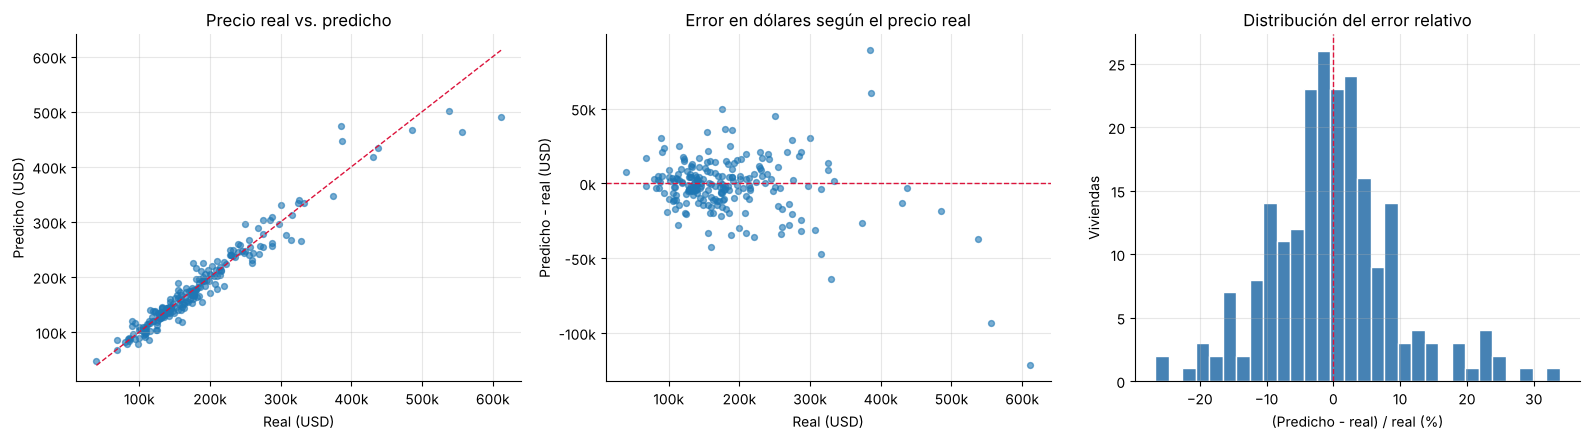

Error absoluto: mediana $8,352 | percentil 90 $30,162 | máximo $121,668
Viviendas con error menor al 10 % del precio: 77% | con error mayor al 20 %: 5%
Viviendas de más de $400,000: 6 | subestimadas: 6 | error medio $-47,849
Sin las 10 viviendas peor estimadas, el RMSE bajaría de $20,167 a $13,830


In [16]:
CONTEXT_COLUMNS = ["Neighborhood", "OverallQual", "GrLivArea", "YearBuilt", "SaleCondition"]

analysis = X_validation[[ID_COLUMN] + CONTEXT_COLUMNS].copy()
analysis["Real"] = y_validation.to_numpy()
analysis["Predicho"] = validation_predictions[selected_name]
analysis["Error"] = analysis["Predicho"] - analysis["Real"]          # > 0: the model overestimates
analysis["Error_abs"] = analysis["Error"].abs()
analysis["Error_%"] = 100 * analysis["Error"] / analysis["Real"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
limits = [analysis[["Real", "Predicho"]].min().min(), analysis[["Real", "Predicho"]].max().max()]
axes[0].scatter(analysis["Real"], analysis["Predicho"], s=18, alpha=0.6)
axes[0].plot(limits, limits, "--", color="crimson", linewidth=1)
axes[0].set(title="Precio real vs. predicho", xlabel="Real (USD)", ylabel="Predicho (USD)")
axes[1].scatter(analysis["Real"], analysis["Error"], s=18, alpha=0.6)
axes[1].axhline(0, linestyle="--", color="crimson", linewidth=1)
axes[1].set(title="Error en dólares según el precio real", xlabel="Real (USD)", ylabel="Predicho - real (USD)")
axes[2].hist(analysis["Error_%"], bins=30, color="steelblue", edgecolor="white")
axes[2].axvline(0, linestyle="--", color="crimson", linewidth=1)
axes[2].set(title="Distribución del error relativo", xlabel="(Predicho - real) / real (%)", ylabel="Viviendas")
for ax in axes[:2]:
    ax.xaxis.set_major_formatter(lambda value, _: f"{value / 1000:,.0f}k")
    ax.yaxis.set_major_formatter(lambda value, _: f"{value / 1000:,.0f}k")
plt.tight_layout()
plt.show()

absolute_error = analysis["Error_abs"]
print(f"Error absoluto: mediana ${absolute_error.median():,.0f} | percentil 90 ${absolute_error.quantile(0.9):,.0f} "
      f"| máximo ${absolute_error.max():,.0f}")
print(f"Viviendas con error menor al 10 % del precio: {(analysis['Error_%'].abs() < 10).mean():.0%} "
      f"| con error mayor al 20 %: {(analysis['Error_%'].abs() > 20).mean():.0%}")
expensive = analysis[analysis["Real"] > 400_000]
print(f"Viviendas de más de $400,000: {len(expensive)} | subestimadas: {(expensive['Error'] < 0).sum()} "
      f"| error medio ${expensive['Error'].mean():+,.0f}")
worst_10 = absolute_error.nlargest(10).index
print(f"Sin las 10 viviendas peor estimadas, el RMSE bajaría de ${rmse(analysis['Real'], analysis['Predicho']):,.0f} "
      f"a ${rmse(analysis['Real'].drop(worst_10), analysis['Predicho'].drop(worst_10)):,.0f}")

**Lectura.**

- **Real vs. predicho:** los puntos siguen la diagonal hasta unos USD 350.000. Por encima, la mayoría queda debajo de la línea, y las seis viviendas de más de USD 400.000 se subestiman todas, en promedio en USD 47.849.
- **Error según el precio:** la dispersión crece con el precio. Hasta USD 250.000, el 93 % de los errores está dentro de ± USD 30.000; los errores de más de USD 80.000 aparecen solo en viviendas de más de USD 380.000.
- **Error relativo:** la distribución está centrada en cero y es aproximadamente simétrica; el 77 % de las viviendas se estima con menos de 10 % de error y solo el 5 % con más de 20 %.

La mitad de las estimaciones se equivoca en menos de USD 8.352 y nueve de cada diez en menos de USD 30.162, pero el peor caso llega a USD 121.668. Sin las 10 viviendas peor estimadas (menos del 5 % de validación) el RMSE bajaría de USD 20.167 a USD 13.830: el RMSE lo determinan pocos casos, no el comportamiento típico.

### 11.2 Tres aciertos y tres errores importantes

In [17]:
CASE_FORMAT = {"Real": "${:,.0f}", "Predicho": "${:,.0f}", "Error": "${:+,.0f}", "Error_%": "{:+.1f}%",
               "GrLivArea": "{:,.0f}", "YearBuilt": "{:.0f}", "OverallQual": "{:.0f}"}
case_columns = [ID_COLUMN] + CONTEXT_COLUMNS + ["Real", "Predicho", "Error", "Error_%"]

print("Tres predicciones más precisas (menor error absoluto):")
display(analysis.nsmallest(3, "Error_abs")[case_columns].style.format(CASE_FORMAT).hide(axis="index"))
print("Tres errores más grandes (mayor error absoluto):")
display(analysis.nlargest(3, "Error_abs")[case_columns].style.format(CASE_FORMAT).hide(axis="index"))

Tres predicciones más precisas (menor error absoluto):


Id,Neighborhood,OverallQual,GrLivArea,YearBuilt,SaleCondition,Real,Predicho,Error,Error_%
100626,Gilbert,7,"2,256",2000,Normal,"$236,000","$236,032",$+32,+0.0%
101349,NAmes,5,"1,792",1974,Normal,"$136,000","$136,059",$+59,+0.0%
101346,Gilbert,5,"1,056",1955,Normal,"$145,000","$145,128",$+128,+0.1%


Tres errores más grandes (mayor error absoluto):


Id,Neighborhood,OverallQual,GrLivArea,YearBuilt,SaleCondition,Real,Predicho,Error,Error_%
100015,NridgHt,9,"2,364",2009,Partial,"$611,657","$489,989","$-121,668",-19.9%
101333,StoneBr,9,"2,868",2005,Partial,"$556,581","$463,447","$-93,134",-16.7%
101337,NridgHt,10,"2,084",2007,Partial,"$385,000","$473,988","$+88,988",+23.1%


**Lectura de los aciertos.** Las tres viviendas mejor estimadas (error menor a USD 130) son ventas en condición `Normal`, de calidad media (5 a 7), en barrios con decenas de ventas en los datos (`Gilbert` y `NAmes`) y con precios entre USD 136.000 y USD 236.000, la zona donde se concentra la mayoría de las viviendas de entrenamiento. Es el caso para el que el modelo tiene más ejemplos parecidos.

**Lectura de los errores.** Las tres viviendas peor estimadas comparten un perfil opuesto:

- Las tres son ventas `Partial` (viviendas nuevas, vendidas antes de estar terminadas), construidas entre 2005 y 2009, de calidad 9 o 10, en dos de los tres barrios más caros (`NridgHt` y `StoneBr`).
- Dos se **subestiman** en USD 121.668 y USD 93.134 (20 % y 17 %): se vendieron a más de USD 550.000, y en entrenamiento solo seis viviendas superan los USD 500.000.
- La tercera se **sobrestima** en USD 88.988 (23 %): tiene calidad 10 y está en `NridgHt`, pero se vendió a USD 385.000 con 2.084 pies², por debajo de lo que esas características suelen valer.

Con las mismas variables (barrio caro, calidad máxima, casa nueva) el precio real puede variar más de USD 200.000. Lo que diferencia a estas casas (terminaciones, vistas, grado de avance de la obra al momento de la venta) no está en los datos.

### 11.3 Error por segmentos

In [18]:
def segment_report(segments):
    """Error metrics of the selected model for each segment of the validation set."""
    report = {
        segment: {
            "Viviendas": len(rows),
            "Precio medio": rows["Real"].mean(),
            "RMSE": np.sqrt(np.mean(rows["Error"] ** 2)),
            "MAE": rows["Error_abs"].mean(),
            "MAPE_%": rows["Error_%"].abs().mean(),
            "Sesgo": rows["Error"].mean(),          # > 0: overestimates on average
        }
        for segment, rows in analysis.groupby(segments, observed=True)
    }
    return pd.DataFrame(report).T.rename_axis(segments.name)


SEGMENT_FORMAT = {"Viviendas": "{:.0f}", "Precio medio": "${:,.0f}", "RMSE": "${:,.0f}", "MAE": "${:,.0f}",
                  "MAPE_%": "{:.1f}%", "Sesgo": "${:+,.0f}"}
MIN_SEGMENT_SIZE = 8

price_segment = pd.qcut(analysis["Real"], 4, labels=["Q1 (más baratas)", "Q2", "Q3", "Q4 (más caras)"])
age = X_validation["YrSold"] - X_validation["YearBuilt"]
age_segment = pd.cut(age, bins=[-1, 10, 40, 70, 200], labels=["0-10 años", "11-40 años", "41-70 años", "más de 70 años"])
neighborhood_counts = analysis["Neighborhood"].value_counts()
neighborhood_segment = analysis["Neighborhood"].where(
    analysis["Neighborhood"].map(neighborhood_counts) >= MIN_SEGMENT_SIZE, "Otros barrios (< 8 viviendas)")

condition_counts = analysis["SaleCondition"].value_counts()
condition_segment = analysis["SaleCondition"].where(
    analysis["SaleCondition"].map(condition_counts) >= MIN_SEGMENT_SIZE, "Otras condiciones (< 8 viviendas)")

print("Error por rango de precio real (cuartiles de validación):")
display(segment_report(price_segment.rename("Rango de precio")).style.format(SEGMENT_FORMAT))
print("Error por antigüedad de la vivienda al momento de la venta:")
display(segment_report(age_segment.rename("Antigüedad")).style.format(SEGMENT_FORMAT))
print("Error por condición de venta:")
display(segment_report(condition_segment.rename("Condición de venta")).style.format(SEGMENT_FORMAT))
print("Error por barrio (ordenado por error relativo):")
display(segment_report(neighborhood_segment.rename("Barrio")).sort_values("MAPE_%", ascending=False)
        .style.format(SEGMENT_FORMAT))

Error por rango de precio real (cuartiles de validación):


,Viviendas,Precio medio,RMSE,MAE,MAPE_%,Sesgo
Rango de precio,,,,,,
Q1 (más baratas),55,"$106,986","$11,772","$8,963",8.7%,$+387
Q2,55,"$145,727","$12,495","$8,910",6.0%,"$-1,553"
Q3,54,"$185,633","$15,956","$11,656",6.3%,$-304
Q4 (más caras),55,"$295,042","$32,784","$22,163",6.9%,"$-4,668"


Error por antigüedad de la vivienda al momento de la venta:


,Viviendas,Precio medio,RMSE,MAE,MAPE_%,Sesgo
Antigüedad,,,,,,
0-10 años,61,"$254,202","$30,278","$18,432",6.6%,$-594
11-40 años,57,"$184,431","$14,416","$11,080",6.2%,"$+1,101"
41-70 años,63,"$144,359","$12,272","$9,419",6.9%,"$-1,762"
más de 70 años,38,"$132,559","$17,633","$12,686",8.7%,"$-6,652"


Error por condición de venta:


,Viviendas,Precio medio,RMSE,MAE,MAPE_%,Sesgo
Condición de venta,,,,,,
Abnorml,14,"$177,193","$23,235","$18,091",11.3%,"$-6,135"
Normal,188,"$175,210","$15,355","$10,857",6.2%,$-548
Otras condiciones (< 8 viviendas),5,"$144,894","$22,786","$19,425",15.2%,"$-5,307"
Partial,12,"$333,834","$53,689","$36,653",9.9%,"$-10,158"


Error por barrio (ordenado por error relativo):


,Viviendas,Precio medio,RMSE,MAE,MAPE_%,Sesgo
Barrio,,,,,,
OldTown,14,"$123,516","$18,106","$13,950",11.4%,"$-3,027"
Crawfor,8,"$206,800","$27,664","$22,466",10.5%,"$-22,213"
NridgHt,12,"$347,382","$49,991","$34,953",9.8%,"$+6,318"
Sawyer,10,"$133,020","$12,585","$11,285",8.9%,"$-6,250"
NoRidge,8,"$283,295","$24,763","$20,454",8.2%,"$+4,674"
Mitchel,14,"$142,225","$14,647","$10,865",8.1%,"$+3,636"
Edwards,13,"$113,877","$11,715","$8,298",7.3%,"$-4,412"
Otros barrios (< 8 viviendas),26,"$211,993","$25,515","$16,030",7.3%,"$-2,414"
BrkSide,12,"$118,508","$11,394","$8,071",6.8%,"$-1,821"


**Lectura.**

- **Rango de precio.** En dólares, el error crece con el precio: el RMSE del cuartil más caro (USD 32.784) casi triplica al del más barato (USD 11.772). En términos relativos ocurre lo contrario: el mayor error porcentual está en las viviendas más baratas (8,7 %), donde USD 9.000 pesan mucho sobre un precio de USD 107.000. El cuartil más caro además se subestima en promedio (sesgo de USD −4.668).
- **Antigüedad.** Las viviendas de 0 a 10 años tienen el mayor error en dólares (RMSE USD 30.278) porque son las más caras y concentran las ventas `Partial`. Las de más de 70 años tienen el mayor error relativo (8,7 %) y se subestiman en USD 6.652 en promedio: su precio depende del estado de conservación y de las reformas, que las variables describen solo en parte.
- **Condición de venta.** Es el corte que mejor separa los casos difíciles. En las 188 ventas `Normal` el RMSE es USD 15.355 y el error relativo 6,2 %. En las 12 ventas `Partial` el RMSE sube a USD 53.689, y en las 14 `Abnorml` (ejecuciones, ventas forzadas) el error relativo es 11,3 %.
- **Barrio.** Los barrios con muchas ventas y viviendas homogéneas se estiman bien: `NWAmes`, `CollgCr` y `NAmes` tienen errores relativos de 4 % a 5 %. Los peores son `OldTown` (11,4 %, el barrio más antiguo), `Crawfor` (10,5 %, subestimado en USD 22.213 en promedio, con solo 8 viviendas) y `NridgHt` (9,8 %, RMSE de USD 49.991, el barrio de las casas nuevas más caras).

Los segmentos con menos de 15 viviendas dan estimaciones poco precisas del error; los leemos como indicios, no como mediciones firmes.

### 11.4 Qué variables usa el modelo

La importancia por permutación desordena una variable por vez en validación y mide cuánto aumenta el RMSE. Indica cuánto depende el modelo de cada variable original para predecir viviendas nuevas, sin importar cómo se haya transformado dentro del flujo.

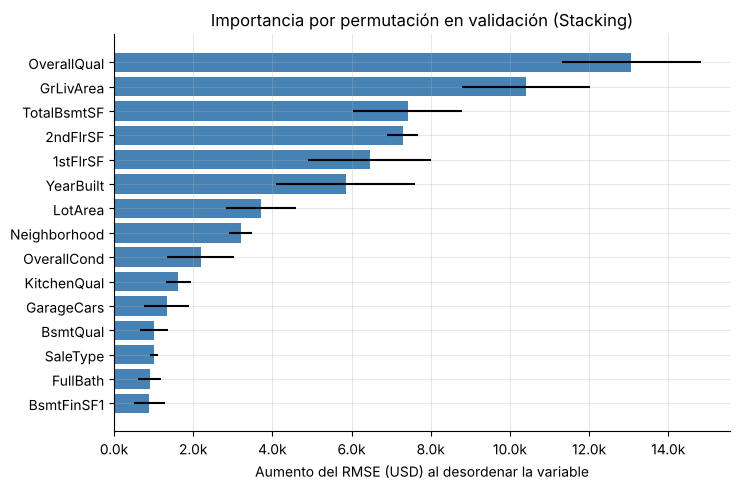

,Aumento medio del RMSE,Desvío
OverallQual,"$13,062","$1,756"
GrLivArea,"$10,409","$1,623"
TotalBsmtSF,"$7,419","$1,374"
2ndFlrSF,"$7,293",$387
1stFlrSF,"$6,455","$1,560"
YearBuilt,"$5,850","$1,749"
LotArea,"$3,711",$891
Neighborhood,"$3,202",$291


Tiempo: 30 s


In [19]:
start = time.time()
importance = permutation_importance(
    fitted_models[selected_name], X_validation, y_validation, scoring="neg_root_mean_squared_error",
    n_repeats=5, random_state=RANDOM_STATE, n_jobs=N_JOBS)
importance = (pd.DataFrame({"Aumento medio del RMSE": importance.importances_mean,
                            "Desvío": importance.importances_std}, index=X_validation.columns)
              .drop(index=ID_COLUMN).sort_values("Aumento medio del RMSE", ascending=False).head(15))

fig, ax = plt.subplots(figsize=(7.5, 5))
ax.barh(importance.index[::-1], importance["Aumento medio del RMSE"][::-1], xerr=importance["Desvío"][::-1],
        color="steelblue")
ax.set(title=f"Importancia por permutación en validación ({selected_name})",
       xlabel="Aumento del RMSE (USD) al desordenar la variable")
ax.xaxis.set_major_formatter(lambda value, _: f"{value / 1000:,.1f}k")
plt.tight_layout()
plt.show()
display(importance.head(8).style.format("${:,.0f}"))
print(f"Tiempo: {time.time() - start:.0f} s")

**Lectura.** El modelo se apoya, en este orden, en la calidad general (`OverallQual`: desordenarla aumenta el RMSE en USD 13.062), la superficie habitable (`GrLivArea`, USD 10.409), las superficies de sótano y de cada planta, el año de construcción, el tamaño del lote y el barrio. Coincide con las variables que el EDA encontró más correlacionadas con el precio.

Las variables correlacionadas entre sí se reparten la importancia: las superficies (`GrLivArea`, `1stFlrSF`, `2ndFlrSF`, `TotalBsmtSF`) alimentan además a `TotalSF` y a las interacciones con la calidad, así que el peso del tamaño en conjunto es mayor que el de cualquiera de ellas por separado.

### 11.5 Qué limitaciones explican los errores

1. **Pocas viviendas caras para aprender.** En entrenamiento solo seis viviendas superan los USD 500.000. El modelo conoce mal ese rango y tiende a acercar sus predicciones a los precios más habituales: por eso subestima el cuartil superior.
2. **Faltan variables que definen el precio en la gama alta y en las casas antiguas.** Terminaciones, vistas, estado real de conservación y calidad de las reformas no están en el dataset. `OverallQual` tiene un máximo de 10 y no distingue entre casas de calidad máxima que se venden a precios muy distintos.
3. **Las ventas que no son de mercado no siguen la misma regla.** En una venta `Partial` el precio corresponde a una casa sin terminar; en una `Abnorml`, a una operación forzada. El modelo conoce la condición de venta, pero con 12 a 14 casos por categoría no puede aprender un ajuste fino.
4. **El logaritmo prioriza el error relativo.** Entrenar en escala logarítmica reparte el esfuerzo en proporción al precio; un 15 % de error en una casa de USD 600.000 son USD 90.000, y esos casos dominan el RMSE en dólares.
5. **Barrios con pocas ventas.** En los barrios chicos el efecto del barrio se estima con pocos ejemplos o queda agrupado con otros niveles poco frecuentes.

De acá sale una regla práctica para detectar los casos que necesitan revisión humana: ventas que no sean `Normal`, estimaciones por encima de USD 350.000 y viviendas de más de 70 años.

## 12. Verificaciones de fuga de datos y reproducibilidad

Cinco comprobaciones ejecutables. Si alguna falla, la celda se detiene con un error.

1. **Los estadísticos aprendidos salen solo de entrenamiento:** las medianas de `LotFrontage` por barrio guardadas en el modelo deben coincidir con las calculadas solo con entrenamiento.
2. **La regla de ventas atípicas no tocó validación.**
3. **Prueba del target mezclado:** se desordena `SalePrice` al azar y se repite la validación cruzada. Sin relación real entre variables y precio, un flujo sin fugas no puede superar a predecir la mediana; si lo hiciera, estaría recibiendo información del precio por otra vía.
4. **Reproducibilidad:** reajustar el modelo elegido debe dar exactamente las mismas predicciones.
5. **El flujo acepta un archivo con formato de test:** sin `SalePrice`, con las columnas en otro orden, con un barrio, un material y un código de vivienda que no existen en entrenamiento, con faltantes en columnas que en entrenamiento no los tienen y con columnas completamente vacías.

In [20]:
start = time.time()
selected_pipeline = fitted_models[selected_name].regressor_
first_member = selected_pipeline.estimators_[0] if hasattr(selected_pipeline, "estimators_") else selected_pipeline
fitted_engineer = first_member.named_steps["features"]

# 1) Learned statistics come from the training partition only.
expected_medians = X_train.groupby("Neighborhood")["LotFrontage"].median()
pd.testing.assert_series_equal(fitted_engineer.lot_frontage_by_neighborhood_.sort_index(),
                               expected_medians.sort_index(), check_names=False)
pooled_medians = pd.concat([X_train, X_validation]).groupby("Neighborhood")["LotFrontage"].median()
n_changed = int((~np.isclose(pooled_medians, expected_medians.reindex(pooled_medians.index), equal_nan=True)).sum())
print(f"1) Las medianas de LotFrontage por barrio guardadas en el modelo coinciden con las de entrenamiento "
      f"(con validación incluida habrían cambiado en {n_changed} de {len(pooled_medians)} barrios).")

# 2) The outlier rule touched the training partition only.
assert not atypical_sale_mask(train_clean).any() and len(X_validation) == len(validation_df)
print(f"2) Regla de ventas atípicas: {len(outlier_rows)} filas excluidas de entrenamiento, 0 de validación.")

# 3) Shuffled-target canary: without a real relation between X and y, a leak-free flow cannot beat the median.
shuffled_target = pd.Series(np.random.RandomState(RANDOM_STATE).permutation(y_train.to_numpy()), index=y_train.index)
canary = evaluate_cv(candidates["ElasticNet"], X_train, shuffled_target)
baseline = evaluate_cv(DummyRegressor(strategy="median"), X_train, shuffled_target)
assert canary["RMSE_CV"] > 0.95 * baseline["RMSE_CV"], "El flujo predice un target mezclado: posible fuga."
print(f"3) Target mezclado: RMSE CV del flujo = ${canary['RMSE_CV']:,.0f} vs. ${baseline['RMSE_CV']:,.0f} "
      f"de predecir la mediana -> no aprende nada, como corresponde.")

# 4) Reproducibility: refitting the selected flow gives exactly the same predictions.
refit_predictions = clone(candidates[selected_name]).fit(X_train, y_train).predict(X_validation)
assert np.allclose(refit_predictions, validation_predictions[selected_name])
print("4) Reajustar el modelo elegido reproduce exactamente las mismas predicciones.")

# 5) The flow accepts a test-like file: no SalePrice, shuffled columns, unseen levels, new missing values.
NEW_MISSING = ["GarageArea", "GarageCars", "TotalBsmtSF", "LotFrontage", "KitchenQual", "MSZoning"]
stress = X_validation.sample(frac=1.0, axis=1, random_state=RANDOM_STATE).copy()
stress = stress.astype({column: float for column in NEW_MISSING if is_numeric(stress[column])})
first_row, second_row = stress.index[:2]
stress.loc[first_row, "Neighborhood"] = "BarrioNuevo"
stress.loc[first_row, "Exterior1st"] = "MaterialNuevo"
stress.loc[first_row, "MSSubClass"] = 999
stress.loc[second_row, NEW_MISSING] = np.nan
stress_predictions = fitted_models[selected_name].predict(stress)
assert np.isfinite(stress_predictions).all() and (stress_predictions > 0).all()
assert np.allclose(stress_predictions[2:], validation_predictions[selected_name][2:])
empty_column = X_validation.assign(PoolQC=np.nan, Alley=np.nan)   # read by pandas as numeric columns
assert np.isfinite(fitted_models[selected_name].predict(empty_column)).all()
print("5) Archivo tipo test con columnas desordenadas, niveles nunca vistos, faltantes nuevos y columnas "
      "vacías: predicciones válidas, y las filas no alteradas dan exactamente el mismo precio.")
print(f"Tiempo: {time.time() - start:.0f} s")

1) Las medianas de LotFrontage por barrio guardadas en el modelo coinciden con las de entrenamiento (con validación incluida habrían cambiado en 9 de 25 barrios).
2) Regla de ventas atípicas: 2 filas excluidas de entrenamiento, 0 de validación.


3) Target mezclado: RMSE CV del flujo = $83,481 vs. $81,327 de predecir la mediana -> no aprende nada, como corresponde.


4) Reajustar el modelo elegido reproduce exactamente las mismas predicciones.


5) Archivo tipo test con columnas desordenadas, niveles nunca vistos, faltantes nuevos y columnas vacías: predicciones válidas, y las filas no alteradas dan exactamente el mismo precio.
Tiempo: 10 s


**Lectura.** Las cinco verificaciones pasan.

- Las medianas guardadas coinciden con las de entrenamiento, y habrían sido distintas en 9 de 25 barrios si validación hubiera participado: el transformador no vio validación.
- Con el precio mezclado el flujo obtiene un RMSE de USD 83.481, peor que predecir la mediana (USD 81.327): no hay información del target filtrándose.
- Reajustar reproduce las predicciones exactas, y un archivo con formato de test con niveles y faltantes nuevos se procesa sin errores y sin alterar el resto de las predicciones. Es la evidencia de que el notebook puede recibir el test de la cátedra sin cambios en el código.

## 13. Modelo final y predicciones para el archivo de test

La configuración quedó elegida usando solo los datos de desarrollo. Para la versión final reentrenamos esa misma configuración (mismo flujo, mismos hiperparámetros) con **todos los datos de desarrollo**, entrenamiento más validación: 219 viviendas adicionales le dan al modelo más ejemplos, en particular de los rangos de precio menos frecuentes. La regla de ventas atípicas se aplica igual que antes.

Ese modelo ya no se puede evaluar con validación, porque ahora la conoce; la estimación de su desempeño es la de las secciones 8 y 10.

La celda de predicción lee `TEST_PATH`, comprueba que estén las 79 columnas explicativas, aplica el flujo ajustado (el mismo preprocesamiento aprendido en entrenamiento) y escribe `predicciones_test.csv`. Si el archivo de test incluyera `SalePrice`, además informa RMSE y MAE. Si el archivo no está, lo avisa y ensaya el mismo camino con la partición de validación sin la columna de precio.

In [21]:
start = time.time()
development_df = pd.concat([train_df, validation_df], ignore_index=True)
development_clean = development_df[~atypical_sale_mask(development_df)].reset_index(drop=True)

final_model = clone(candidates[selected_name]).fit(development_clean.drop(columns=[TARGET]),
                                                  development_clean[TARGET])
print(f"Modelo final: {selected_name}, reentrenado con {len(development_clean)} viviendas "
      f"({len(development_df) - len(development_clean)} ventas atípicas excluidas).")
if selected_name == "Stacking":
    final_weights = final_model.regressor_.final_estimator_.coef_
    print("Pesos del meta-modelo final:", {name: round(float(weight), 3) for name, weight in zip(ENSEMBLE_MEMBERS, final_weights)})
print(f"Tiempo: {time.time() - start:.0f} s")

Modelo final: Stacking, reentrenado con 1239 viviendas (2 ventas atípicas excluidas).
Pesos del meta-modelo final: {'ElasticNet': 0.021, 'SVR': 0.753, 'GradientBoosting': 0.239}
Tiempo: 9 s


In [22]:
def predict_prices(model, features):
    """Apply the fitted flow (same preprocessing learned in training) and return prices in USD."""
    missing = [column for column in FEATURE_COLUMNS if column not in features.columns]
    if missing:
        raise ValueError(f"Al archivo le faltan columnas requeridas: {missing}")
    identifiers = features[ID_COLUMN] if ID_COLUMN in features.columns else pd.RangeIndex(1, len(features) + 1)
    return pd.DataFrame({ID_COLUMN: np.asarray(identifiers), TARGET: model.predict(features[FEATURE_COLUMNS])})


if TEST_PATH.is_file():
    test_df = pd.read_csv(TEST_PATH)
    test_predictions = predict_prices(final_model, test_df)
    test_predictions.to_csv(PREDICTIONS_PATH, index=False)
    print(f"{len(test_predictions)} predicciones guardadas en {PREDICTIONS_PATH}")
    display(test_predictions.head().style.format({TARGET: "${:,.2f}"}).hide(axis="index"))
    display(test_predictions[TARGET].describe().to_frame("Predicción (USD)").T.style.format("{:,.0f}"))
    if TARGET in test_df.columns:   # only if the file happens to include the real prices
        test_scores = score_predictions(test_df[TARGET], test_predictions[TARGET])
        print(f"Test con precios reales -> RMSE = ${test_scores['RMSE']:,.0f} | MAE = ${test_scores['MAE']:,.0f}")
else:
    print(f"No se encontró {TEST_PATH}. Al copiar el archivo de test en esa ruta y volver a ejecutar el notebook, "
          f"esta celda genera {PREDICTIONS_PATH} sin cambiar el código.")
    dry_run = predict_prices(final_model, validation_df.drop(columns=[TARGET]))
    print(f"Ensayo del mismo flujo con la partición de validación sin SalePrice: {len(dry_run)} predicciones generadas.")
    display(dry_run.head().style.format({TARGET: "${:,.2f}"}).hide(axis="index"))

No se encontró ../ames-housing-desarrollo-estudiantes/test.csv. Al copiar el archivo de test en esa ruta y volver a ejecutar el notebook, esta celda genera predicciones_test.csv sin cambiar el código.
Ensayo del mismo flujo con la partición de validación sin SalePrice: 219 predicciones generadas.


Id,SalePrice
101377,"$163,896.24"
100577,"$194,205.56"
101054,"$216,233.85"
100150,"$103,004.80"
100867,"$186,986.20"


**Lectura.** El modelo final es el Stacking reentrenado con 1.239 viviendas. Los pesos del meta-modelo casi no cambian respecto de los obtenidos solo con entrenamiento (SVR 0,75, Gradient Boosting 0,24, ElasticNet 0,02), lo que indica que la combinación es estable frente a un cambio en los datos.

Si `test.csv` está en la carpeta de datos, la celda muestra las primeras predicciones y un resumen de su distribución, y deja el archivo `predicciones_test.csv` junto al notebook. Si todavía no está, muestra el ensayo del mismo camino con la partición de validación.

## 14. Límites de la solución

**Qué no puede hacer el modelo**

- **No reemplaza una tasación ni sirve para decidir créditos.** Es una estimación estadística con un error típico de USD 13.000 y errores ocasionales de más de USD 100.000. Tampoco informa cuán segura es cada estimación: devuelve un valor, sin intervalo.
- **No ve lo que no está en las variables.** Estado real de conservación, calidad de las terminaciones, vistas, ruido, distribución interior o urgencia de quien vende no figuran en los datos, y son justamente lo que diferencia a dos casas con las mismas características declaradas.
- **No estima bien las ventas que no son de mercado.** En ventas `Partial` y `Abnorml` el error es mucho mayor (sección 11.3). Además, las ventas del tipo de las dos que excluimos del entrenamiento (casas muy grandes vendidas sin terminar) no las puede anticipar: las sobrestimaría por mucho.
- **Es menos confiable en los extremos.** Subestima las viviendas más caras, porque aprendió de muy pocas, y su error relativo es mayor en las más baratas y en las de más de 70 años.
- **No puede valorar lo que nunca vio.** Un barrio, un material o un tipo de vivienda que no esté en los datos de entrenamiento se trata como "nivel poco frecuente": el modelo predice igual, pero sin la información de ubicación, que es de las más importantes.

**Límites de los datos: Ames, 2006 a 2010**

- **Lugar.** Ames es una ciudad universitaria chica del medio oeste de Estados Unidos. Los barrios, los tipos de construcción (sótanos, garages para varios autos, revestimientos), las unidades (pies cuadrados, dólares) y las preferencias de quienes compran son propios de ese mercado. El modelo no se puede aplicar a otra ciudad ni a otro país, ni siquiera reentrenándolo sin revisar las variables: `Neighborhood` no tiene equivalente y muchas características no existen o no pesan igual en otros mercados.
- **Período.** Los precios son nominales de 2006 a julio de 2010 (el último año está incompleto). En esos años el precio mediano se mantuvo entre USD 155.000 y USD 167.500, según el EDA, por lo que el modelo no aprendió ninguna tendencia de precios; usarlo hoy daría valores sistemáticamente bajos, porque no conoce la inflación ni la evolución posterior del mercado. El período incluye además la crisis inmobiliaria de 2008, un contexto particular.
- **Cantidad y composición.** Son 1.241 viviendas de desarrollo. Dos barrios y varias categorías tienen menos de 10 casos, y solo seis viviendas superan los USD 500.000; lo que el modelo sabe de esos grupos es frágil.
- **Solo ventas concretadas.** Los datos son operaciones cerradas; no hay propiedades que no se vendieron ni precios de publicación.

**Límites de la evaluación**

- El desempeño informado sale de una validación de 219 viviendas y de una validación cruzada cuyo RMSE varía unos USD 2.200 entre folds: el RMSE sobre el test puede diferir en ese orden sin que nada haya fallado.
- La partición de validación no contiene ventas atípicas como las excluidas del entrenamiento. Si el test tuviera alguna, el RMSE sería bastante mayor.

## 15. Conclusiones

**Qué hace la solución.** Estima el precio de venta de una vivienda de Ames a partir de 79 características. Es un único flujo de scikit-learn que recibe los datos tal como vienen en el CSV, los prepara y combina tres modelos clásicos (SVR, Gradient Boosting y ElasticNet) mediante un Stacking. Se eligió y se evaluó con 1.241 viviendas vendidas entre 2006 y 2010, y la versión final se entrenó con 1.239 de ellas.

**Con qué precisión.** Sobre 219 viviendas que no participaron en ninguna decisión:

- Una estimación típica se equivoca en unos **USD 13.000** (MAE de USD 12.929), cerca del 7 % del precio. La mitad de las estimaciones queda a menos de USD 8.400 del precio real y tres de cada cuatro a menos del 10 %.
- El **RMSE es de USD 20.167**. Es mayor que el MAE porque pocos casos pesan mucho: una de cada diez estimaciones se equivoca en más de USD 30.000 y la peor lo hizo en USD 121.668. Sin las diez viviendas peor estimadas el RMSE sería de USD 13.830.
- Como referencia, predecir siempre el precio mediano tiene un RMSE de alrededor de USD 81.000: el modelo reduce ese error a la cuarta parte.

**Qué decisiones explican ese desempeño.** Respondiendo a la pregunta central, la evidencia de la tabla de experimentos señala tres, en este orden:

1. **Excluir del entrenamiento dos ventas atípicas** (casas enormes vendidas sin terminar). Es la decisión de mayor impacto: baja el RMSE de validación cruzada del modelo lineal en USD 5.404 y el de Gradient Boosting en USD 3.514. Son 2 filas de 1.022.
2. **Modelar el logaritmo del precio.** Baja el RMSE del modelo lineal en USD 3.279, porque vuelve casi lineal la relación del precio con la calidad y la superficie.
3. **Elegir bien la familia de modelos y combinarlas.** Con la misma preparación, los modelos de forma suave (ElasticNet USD 21.429, SVR USD 21.002) superan con claridad a los de árboles (Gradient Boosting USD 24.336, Random Forest USD 27.198), y el Stacking mejora al mejor modelo individual (USD 20.709) y es más estable.

El resto de la preparación (faltantes con significado, codificación ordinal, agrupación de niveles raros, variables nuevas, corrección de asimetría) no produjo mejoras que se distingan del ruido. La mantenemos porque representa correctamente los datos y hace que el flujo resista un archivo nuevo, no porque baje el error. Box-Cox y la eliminación de variables colineales se probaron y se descartaron. La validación cruzada (USD 20.709) anticipó bien el resultado en validación (USD 20.167), lo que respalda que las decisiones no se ajustaron a una partición en particular.

**Qué no hace.** No es una tasación ni una base para otorgar créditos. Falla sobre todo en tres situaciones: viviendas de más de USD 350.000, que tiende a subestimar; ventas que no son de mercado (casas sin terminar, ejecuciones), donde el error es mucho mayor (RMSE de USD 53.689 en ventas `Partial` contra USD 15.355 en ventas normales); y viviendas muy antiguas, cuyo estado real no está en los datos. Vale solo para Ames y para los precios de 2006 a 2010: aplicado a otro lugar o a otro momento daría valores sin sustento.

**Qué haríamos después.**

1. **Acompañar cada estimación con un intervalo y una marca de revisión.** El análisis de errores mostró que el modelo es confiable en ventas normales de precio medio (error relativo de 6 %) y poco confiable en perfiles identificables de antemano. Con regresión cuantílica o predicción conforme se puede entregar un rango junto al valor y derivar a revisión humana las viviendas con rango amplio, que es el uso previsto en el escenario.
2. **Mejorar la gama alta.** El mayor aporte al RMSE viene de las viviendas caras y nuevas. Probaríamos dar más peso a esas viviendas en el entrenamiento, o un modelo específico para ventas `Partial`, midiendo con el mismo esquema si baja el error de ese segmento sin empeorar el resto.
3. **Reemplazar ElasticNet en el ensamble.** El meta-modelo le asignó un peso casi nulo porque se parece demasiado a SVR. Un tercer modelo base con errores distintos (por ejemplo, vecinos más cercanos sobre ubicación y tamaño) podría aportar más.


## Cambios de la versión 3 respecto de v2 y v1

**Resultado sobre la misma partición de validación (219 viviendas)**

| | v1 | v2 | v3 (este notebook) |
|---|---|---|---|
| Modelo elegido | Random Forest | Voting (ElasticNet + Gradient Boosting) | Stacking (ElasticNet + SVR + Gradient Boosting) |
| RMSE en validación | USD 28.601 | USD 21.682 | **USD 20.167** |
| MAE en validación | USD 17.249 | USD 13.656 | **USD 12.929** |
| Cómo se eligió | RMSE en validación | RMSE logarítmico en CV de 5 folds | RMSE en dólares (métrica oficial) en CV repetida 5×3 |
| Tiempo de ejecución (2 núcleos) | — | ≈ 11 min | ≈ 6 min |

La información análoga al modelado v1 se obtuvo de la tabla comparativa entre el modelado v1 y v2 (presente en el segundo notebook); por esta razón hay algunos datos faltantes en las tablas. 


**Qué se cambió y por qué (ordenado por requisito de la consigna)**

| Requisito de la consigna | v1 | v2 | v3 |
|---|---|---|---|
| Recibir el archivo de test sin editar código | — | No previsto: no había ruta de test ni celda de predicción | `TEST_PATH` en la primera celda de código; la sección 13 lee el archivo, aplica el mismo flujo y escribe `predicciones_test.csv`. Si el archivo no está, el notebook igual corre y ensaya el flujo con validación |
| Un único flujo reutilizable | — | `Pipeline`, pero el logaritmo del precio se aplicaba y deshacía a mano fuera del flujo | Todo dentro de un solo estimador (`TransformedTargetRegressor` + `Pipeline`): entra el DataFrame crudo y sale el precio en dólares |
| Correr de principio a fin, reproducible | — | Celda `%pip install`, archivo `.joblib` intermedio, valores de v1 escritos a mano | Sin instalaciones ni archivos intermedios; semillas en todos los pasos con azar; una verificación comprueba que reajustar da las mismas predicciones |
| Sin fuga de datos | — | Correcto, con una excepción: el efecto de quitar outliers se medía sobre validación | Todo se decide con validación cruzada sobre entrenamiento; validación solo se usa para el reporte final |
| Mismo esquema de evaluación para comparar | Validación | Mezcla: CV en logaritmos para elegir, validación para outliers, tablas con métricas distintas | Una sola función (`evaluate_cv`) para todos los experimentos: CV repetida 5×3, RMSE y MAE en dólares, diferencias pareadas con su error estándar |
| Preprocesamiento no trivial | Outliers conservados; `log1p` fijo en una lista de columnas; superficies, baños y edades | Faltantes con significado en categóricas y `MasVnrArea`; ordinales; agrupación de niveles raros; Box-Cox | Además: faltantes numéricos de "ausencia" → 0, moda para faltantes reales en categóricas, esquema de tipos fijado en entrenamiento (un test con columnas vacías o niveles nuevos no rompe el flujo) |
| Tabla de experimentos (incluye los que no mejoran) | — | Dos ablaciones sueltas (Box-Cox y outliers) | Sección 9: 17 experimentos con preparación, modelo e hiperparámetros, RMSE, MAE y decisión |
| Comparar familias de modelos | Regresión lineal, Random Forest, Gradient Boosting (grillas chicas) | ElasticNet, RF, GBR, Voting, Stacking | Se agrega SVR (kernel RBF), que resulta el mejor modelo individual y el de más peso en el Stacking |
| Analizar dónde falla | MAE y RMSE globales | Error por rango de precio y los 8 peores casos | Tres aciertos y tres errores comentados; error por rango de precio, antigüedad, condición de venta y barrio; explicación de las causas |
| Límites y conclusión propia | — | Sección "completá con tus números" | Secciones 14 y 15 redactadas con los resultados de la ejecución |
| Fuentes | — | No | Sección 16: qué se tomó de cada fuente, cómo se adaptó y qué resultado dio |

**Otras diferencias con v2**

- **Box-Cox** deja de ser la transformación por defecto: en la comparación controlada (P8a vs. P8b) le gana a `log1p` por USD 88 de RMSE, menos que el ruido entre folds, así que se usa `log1p`, que es más simple de explicar. Box-Cox queda como experimento documentado.
- **Métricas:** se reportan RMSE y MAE en dólares (lo que pide la consigna) más MAPE y R² como apoyo; se quitaron RMSPE y "RMSE % del precio medio" de las tablas.
- **Código en inglés, documentación en español.** Los textos de las celdas dejaron de ser instrucciones de lectura genéricas ("si baja… si sube…") y describen los resultados obtenidos.
- **No se incluyó target encoding** para `Neighborhood`: en una prueba exploratoria hecha fuera del notebook no mejoró al one-hot con agrupación de niveles raros, y `TargetEncoder` cambia de interfaz entre versiones de scikit-learn.

## 16. Fuentes consultadas y qué tomamos de cada una

| Fuente | Idea que tomamos | Cómo la adaptamos | Resultado en nuestras pruebas | Decisión |
|---|---|---|---|---|
| De Cock (2011), publicación original y documentación del dataset | Las viviendas de más de 4.000 pies² incluyen ventas que no representan valores de mercado, y recomienda quitarlas. El significado de `NA` en cada variable | Quitamos solo las dos mal valuadas, con una regla que también mira el precio, y solo del entrenamiento; conservamos las dos grandes con precio coherente | P3: −5.404 de RMSE en Ridge y −3.514 en Gradient Boosting. P4: sin cambio en la métrica | Se mantienen ambas |
| Marcelino, *Comprehensive Data Exploration with Python* (EDA) | Transformar `SalePrice` con logaritmo para acercarlo a una normal; mirar `GrLivArea` contra el precio para detectar extremos | Aplicamos el logaritmo dentro del flujo para que el modelo devuelva dólares. A diferencia de ese trabajo, que resuelve los faltantes eliminando las columnas que los tienen, los tratamos según su significado | P2: −3.279 de RMSE en Ridge; +956 en Gradient Boosting | Se mantiene el logaritmo |
| Serigne, *Stacked Regressions: Top 4% on Leaderboard* (comparación de modelos) | `TotalSF`; faltantes como `"None"`/0 y `LotFrontage` por barrio; Box-Cox en variables con asimetría mayor a 0,75; combinar modelos lineales y de árboles en un Stacking | Ese trabajo preprocesa train y test juntos; acá todo se aprende dentro del `Pipeline`, solo con entrenamiento. Usamos únicamente modelos de scikit-learn (sin XGBoost ni LightGBM) y estimamos el exponente de Box-Cox por columna en lugar de fijarlo | P7: −261 en Ridge. P8b (Box-Cox): USD 88 mejor que `log1p`. M6 (Stacking): USD 20.709, el mejor candidato | Se mantienen `TotalSF` y el Stacking; se descarta Box-Cox |
| scikit-learn MOOC, *The Ames housing dataset*, y guía de usuario de scikit-learn | Encapsular el preprocesamiento por tipo de columna con `ColumnTransformer` y `Pipeline`; transformar el target con `TransformedTargetRegressor`; importancia por permutación | Agregamos dos transformadores propios (`AmesFeatureEngineer`, `SkewCorrector`) con la interfaz de scikit-learn | Verificaciones de la sección 12 | Se mantiene |

**Referencias**

- De Cock, D. (2011). Ames, Iowa: Alternative to the Boston Housing Data as an End of Semester Regression Project. *Journal of Statistics Education*, 19(3). https://doi.org/10.1080/10691898.2011.11889627
- Kaggle. *House Prices: Advanced Regression Techniques*. https://www.kaggle.com/competitions/house-prices-advanced-regression-techniques
- Marcelino, P. *Comprehensive Data Exploration with Python*. https://www.kaggle.com/code/pmarcelino/comprehensive-data-exploration-with-python
- Serigne. *Stacked Regressions: Top 4% on Leaderboard*. https://www.kaggle.com/code/serigne/stacked-regressions-top-4-on-leaderboard
- scikit-learn MOOC. *The Ames housing dataset*. https://inria.github.io/scikit-learn-mooc/python_scripts/datasets_ames_housing.html
- scikit-learn. *User Guide*: Column Transformer with Mixed Types, Transforming target in regression, Stacked generalization, Permutation feature importance. https://scikit-learn.org/stable/user_guide.html